<a href="https://colab.research.google.com/github/OJB-Quantum/Notebooks-for-Ideas/blob/main/CuDSS_Micromagnetic_Standard_Problem_4_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

# cuDSS micromagnetics: Standard Problem 4

## First-principles primer

Micromagnetics describes a ferromagnet through a continuous unit magnetization field, whereby exchange directly favors neighboring alignment and the demagnetizing field promotes flux closure near the sample boundaries. Applied magnetic fields directly drive precession, while Gilbert damping directs the moments toward a lower-energy state and indirectly sets how quickly oscillations decay after the field changes [1]. This calculation follows field-driven reversal in a thin permalloy rectangle, using cuDSS to solve the Gilbert velocity at each classical RK4 stage and Matplotlib to display its evolving spatial texture [2–4].

Historically, Landau and Lifshitz describe precession with damping, Gilbert introduces derivative-dependent damping, and Newell and colleagues supply an analytic tensor for the fields produced by uniformly magnetized rectangular cells [1, 2]. Alouges develops the tangent-plane approach that guides the zero-field S-state preparation used here, while later GPU micromagnetic work demonstrates the value of standard-problem comparisons for checking numerical solvers [3, 4]. McMichael, Koch, Schrefl, and Eicke develop Standard Problem 4 around a common equilibrium S-state, permitting two applied-field cases to expose differences between smooth rotation and spatially complicated reversal.

## Acronyms and terms

| Term | Full name or origin | Role in this calculation |
|---|---|---|
| Micromagnetics | *Micro*, meaning small, joined with magnetics | Continuum magnetization at scales that resolve magnetic textures |
| cuDSS | NVIDIA CUDA Direct Sparse Solver | Native sparse direct solution at each time step |
| CUDA | Compute Unified Device Architecture | NVIDIA GPU computing platform |
| GPU | Graphics processing unit | Device that holds the evolving magnetization and numerical fields |
| CuPy | NumPy-compatible GPU array library | Array operations, sparse exchange products, reductions, and FFTs |
| NVRTC | NVIDIA Runtime Compilation library | Compiles CuPy GPU kernels from matching CUDA headers |
| LLG | Landau–Lifshitz–Gilbert equation | Magnetization precession and damping |
| FFT | Fast Fourier transform | Isolated-sample demagnetizing-field convolution |
| CSR | Compressed sparse row | Sparse matrix storage used by cuDSS |
| RK4 | Classical fourth-order Runge–Kutta method | Four full effective-field evaluations and four cuDSS stage solves per physical time step |
| IMEX | Implicit–explicit | Exchange-implicit zero-field S-state preparation |
| DPI | Dots per inch | Default Matplotlib figure and animation resolution: 200 |
| S-state | Shape-based name for an equilibrium texture with similarly canted end domains | Common starting state for both field cases |
| Zeeman energy | Magnetic interaction named for Pieter Zeeman | Energy associated with the externally applied field |

## Geometry, fields, and symbols

| Symbol | Meaning | Default value or definition |
|---|---|---|
| $\mathbf m=\mathbf M/M_s$ | Normalized magnetization, with $\mathbf M$ the magnetization | $|\mathbf m|=1$ in every cell |
| $L_x,L_y,L_z$ | Sample dimensions along x, y, and z | $500,125,3\ \mathrm{nm}$ |
| $M_s$ | Saturation magnetization | $8.0\times10^5\ \mathrm{A\,m^{-1}}$ |
| $A$ | Exchange stiffness | $1.3\times10^{-11}\ \mathrm{J\,m^{-1}}$ |
| $K$ | Crystalline anisotropy constant | $0$ |
| $\mu_0$ | Vacuum permeability | $4\pi\times10^{-7}\ \mathrm{H\,m^{-1}}$ |
| $\alpha$ | Gilbert damping | $0.02$ during reversal; $1$ during zero-field preparation |
| $\gamma_G$ | Positive Gilbert coefficient for an H field in A/m | $2.211\times10^5\ \mathrm{m\,A^{-1}\,s^{-1}}$ |
| $\gamma_{\rm LL}$ | Corresponding Landau–Lifshitz coefficient | $\gamma_G/(1+\alpha^2)$ |
| $\mathbf B_{\rm ext}=\mu_0\mathbf H_{\rm ext}$ | Applied-field parameter quoted by the benchmark | Case A: $(-24.6,4.3,0)\ \mathrm{mT}$; Case B: $(-35.5,-6.3,0)\ \mathrm{mT}$ |
| $h_x,h_y,h_z$ | Rectangular computational-cell dimensions | $5,5,3\ \mathrm{nm}$ |
| $V_c$ | Computational-cell volume | $h_xh_yh_z$ |
| $N$ | Number of computational cells | $100\times25\times1=2500$ |
| $\Delta_h$ | Axis-weighted discrete Laplacian | Neighbor coefficient $1/h_a^2$ along axis $a$; free exchange boundary |
| $C_{\rm ex}$ | Exchange-field coefficient | $2A/(\mu_0M_s)$ |
| $\mathsf N_{i-j}$ | Volume-averaged Newell tensor between rectangular cells | Includes the finite self term and the physical 3 nm thickness |
| $\Delta t$ | Fixed physical time step during reversal | $0.05\ \mathrm{ps}$ |
| $\theta$ | Implicit exchange weight during zero-field preparation | $1$ |
| $T_i$ | Two-column orthonormal tangent frame at cell $i$ | $\mathbf m_i\times T_{i1}=T_{i2}$ |
| $J$ | Cross-product matrix in the tangent frame | $J_{12}=-1$, $J_{21}=1$, diagonal entries zero |
| $P_{\mathbf m}$ | Orthogonal tangent-plane projector | $I-\mathbf m\mathbf m^{\mathsf T}$ |
| $\mathbf w_i=T_i\mathbf q_i$ | Tangent increment and its two coefficients | The preparation system holds $2N$ unknowns |
| $\mathbf u_i$ | Magnetization at an intermediate RK4 stage | Stages are evaluated without normalization |
| $C(\mathbf u_i)$ | Cross-product matrix | $C(\mathbf u_i)\mathbf v=\mathbf u_i\times\mathbf v$ |
| $\Gamma_i=I-\alpha C(\mathbf u_i)$ | Gilbert velocity matrix at a stage | One $3\times3$ block per cell, totaling $3N$ unknowns |
| $\mathbf F(\mathbf u)$ | Full Gilbert velocity field evaluated at stage state $\mathbf u$ | Exchange, demagnetizing, and applied fields are recomputed at every stage |
| $\mathbf k_1,\mathbf k_2,\mathbf k_3,\mathbf k_4$ | Four RK4 stage velocities | Rates in $\mathrm{s^{-1}}$ |
| $t_0$ | First zero of the spatially averaged x component | Detected at every time step and refined inside its sign-change bracket |

## Governing equations

Permalloy's small crystalline anisotropy motivates the benchmark's exchange, demagnetizing, and Zeeman terms, while its thin geometry makes the shape-induced preference for in-plane magnetization essential to the reversal mechanism. Rectangular cells preserve the specified thickness directly, and a single thickness cell represents magnetization that stays uniform across that cell while the three-dimensional magnetostatic tensor still includes its finite volume [2]. Spatial refinement through `refinement_cell_nm` resolves sharper textures, whereas time-step refinement measures the fourth-order RK4 integration error without changing the shared equilibrium state used by either field case [3, 4].

For a homogeneous material at zero temperature, with no applied current and no crystalline anisotropy, the energy and effective H field satisfy the following definitions, where $\Omega$ denotes the sample volume.

$$
E=A\int_\Omega|\nabla\mathbf m|^2\,\mathrm dV-\frac{\mu_0M_s}{2}\int_\Omega\mathbf m\cdot\mathbf H_d\,\mathrm dV-M_s\int_\Omega\mathbf m\cdot\mathbf B_{\rm ext}\,\mathrm dV.
$$

$$
\mathbf H_{\rm eff}=-\frac{1}{\mu_0M_s}\frac{\delta E}{\delta\mathbf m}=C_{\rm ex}\Delta_h\mathbf m+\mathbf H_d+\frac{\mathbf B_{\rm ext}}{\mu_0},\qquad \mathbf H_{d,i}=-M_s\sum_j\mathsf N_{i-j}\mathbf m_j.
$$

$$
\partial_t\mathbf m=-\gamma_G\mathbf m\times\mathbf H_{\rm eff}+\alpha\mathbf m\times\partial_t\mathbf m,\qquad (\alpha I+\mathbf m\times)\partial_t\mathbf m=\gamma_GP_{\mathbf m}\mathbf H_{\rm eff}.
$$

### RK4 dynamics

At each RK4 stage, cuDSS solves the Gilbert velocity equation for all cells, while CuPy recomputes the complete effective field from that stage's exchange, demagnetizing, and applied-field contributions. Intermediate magnetization vectors enter these equations without normalization, which preserves the classical four-stage method and permits a smooth velocity field away from the unit sphere during the stage calculations. The completed weighted step then normalizes each spin, while the independent zero-field preparation continues to use its exchange-implicit relaxation scheme before either applied field begins.

$$
\Gamma_i(\mathbf u_i)\mathbf F_i(\mathbf u)=-\gamma_G\mathbf u_i\times\mathbf H_{{\rm eff},i}(\mathbf u),\qquad \Gamma_i(\mathbf u_i)=I-\alpha C(\mathbf u_i),\qquad C(\mathbf u_i)\mathbf v=\mathbf u_i\times\mathbf v.
$$

$$
\mathbf k_1=\mathbf F(\mathbf m^n),\qquad \mathbf k_2=\mathbf F(\mathbf m^n+\tfrac12\Delta t\,\mathbf k_1),\qquad \mathbf k_3=\mathbf F(\mathbf m^n+\tfrac12\Delta t\,\mathbf k_2),\qquad \mathbf k_4=\mathbf F(\mathbf m^n+\Delta t\,\mathbf k_3).
$$

$$
\widetilde{\mathbf m}^{n+1}=\mathbf m^n+\frac{\Delta t}{6}(\mathbf k_1+2\mathbf k_2+2\mathbf k_3+\mathbf k_4),\qquad \mathbf m_i^{n+1}=\frac{\widetilde{\mathbf m}_i^{n+1}}{|\widetilde{\mathbf m}_i^{n+1}|}.
$$

### Zero-field preparation

$$
(\alpha I+\mathbf m^n\times)\mathbf w-\gamma_GC_{\rm ex}\theta\Delta t\,P_{\mathbf m^n}\Delta_h\mathbf w=\gamma_G\Delta t\,P_{\mathbf m^n}\mathbf H_{\rm eff}^{n}.
$$

$$
\mathcal A_{ia,jb}=\delta_{ij}(\alpha\delta_{ab}+J_{ab})-\gamma_GC_{\rm ex}\theta\Delta t\,(\Delta_h)_{ij}(T_{ia}\cdot T_{jb}),\qquad \mathcal A\mathbf q=\mathbf b.
$$

$$
\mathbf m_i^{n+1}=\frac{\mathbf m_i^n+T_i\mathbf q_i}{|\mathbf m_i^n+T_i\mathbf q_i|},\qquad \ell_{\rm ex}=\sqrt{\frac{2A}{\mu_0M_s^2}}\simeq5.686\ \mathrm{nm}.
$$

$$
E_{\rm ex}=-AV_c\sum_i\mathbf m_i\cdot\Delta_h\mathbf m_i,\qquad E_d=-\frac{\mu_0M_sV_c}{2}\sum_i\mathbf m_i\cdot\mathbf H_{d,i},\qquad E_Z=-M_sV_c\sum_i\mathbf m_i\cdot\mathbf B_{\rm ext}.
$$

In the smooth resolved regime at fixed mesh, the global RK4 time error scales $\propto(\Delta t)^4$, while centered interior exchange differences have local error $\propto h_a^2$ along each resolved axis $a$. Explicit RK4 requires a stable time step for the resolved exchange and demagnetizing fields, so the refinement controls compare both mean magnetization and first-zero times at smaller time steps and finer meshes.

## Calculation and display

Initialization relaxes the normalized uniform seed $(1,0.25,0.1)$ at zero field, following the OOMMF example, until the unsplit physical angular rate falls below the selected threshold.

## Reuse threshold

Function definitions serve as repeated numerical work.  Meanwhile, setup, checks, preparation, case loops, and figure assembly run directly in their cells. The control `FUNCTION_REUSE_THRESHOLD = 3` means a numerical helper earns its definition after more than three executed calls, including calls inside time loops. A small counter inside each helper automatically records that reuse without a profiler or wrapper functions.

Native-library lifetime management and library callbacks hold explicit interface exceptions because their callers require callable objects. The audit reports each helper's actual count and marks a helper below the threshold as an inline candidate, which permits review after changing the run controls.

## Environment controls

In [1]:
"""This script computes Standard Problem 4 with reusable cuDSS RK4 kernels."""

# --- Definition Controls ---
FUNCTION_REUSE_THRESHOLD = 3
SHOW_DEFINITION_AUDIT = True
from collections import Counter

FUNCTION_CALLS = Counter()

# --- Environment Controls ---
INSTALL_PACKAGES = True
VERBOSE_LIBRARY_PATHS = True
REQUIRED_PACKAGES = (
    'cupy-cuda12x[ctk]==14.2.0',
    'nvidia-cudss-cu12==1.0.0.35',
    'nvidia-cuda-runtime-cu12==12.9.*',
    'nvidia-cuda-nvrtc-cu12==12.9.*',
    'nvidia-cuda-nvcc-cu12==12.9.*',
    'numpy',
    'scipy',
    'matplotlib',
    'psutil',
    'ipywidgets',
)

# --- Standard-Library Bootstrap ---
import ctypes
import importlib.metadata as metadata
import os
from pathlib import Path
import re
import shutil
import subprocess
import sys
import tempfile

_CUDA_HANDLES = []
_CUDA_LIBRARIES = {}

## CUDA 12 setup

In [ ]:
# --- Package Setup ---
before = {
    d.metadata.get('Name', '').lower(): d.version
    for d in metadata.distributions()
    if d.metadata.get('Name', '').lower().startswith(('cupy', 'nvidia-', 'cuda-'))
    or d.metadata.get('Name', '').lower() in ('numpy', 'scipy', 'matplotlib')
}
maps = Path('/proc/self/maps')
loaded_gpu = (
    bool(
        re.search(
            r'/lib(?:cudart|cublas|cufft|cusparse|cudss|nvrtc)\.',
            maps.read_text(errors='replace'),
        )
    )
    if maps.exists()
    else any(n == 'cupy' or n.startswith('cupy.') for n in sys.modules)
)
loaded_python = {name: name in sys.modules for name in ('numpy', 'scipy', 'matplotlib')}
conflicts = sorted(
    name
    for name in before
    if (name == 'cupy' or name.startswith('cupy-cuda')) and name != 'cupy-cuda12x'
)
if INSTALL_PACKAGES:
    uv = shutil.which('uv')
    if uv is None:
        raise RuntimeError('Install uv before this cell: %pip install uv')
    if conflicts:
        if loaded_gpu:
            raise RuntimeError(
                'Restart the Colab session, then run this setup cell first; '
                'a conflicting CuPy stack is already loaded.'
            )
        subprocess.run(
            [uv, 'pip', 'uninstall', '--python', sys.executable, *conflicts], check=True
        )
    subprocess.run(
        [uv, 'pip', 'install', '--python', sys.executable, *REQUIRED_PACKAGES],
        check=True,
    )
after = {
    d.metadata.get('Name', '').lower(): d.version
    for d in metadata.distributions()
    if d.metadata.get('Name', '').lower().startswith(('cupy', 'nvidia-', 'cuda-'))
    or d.metadata.get('Name', '').lower() in ('numpy', 'scipy', 'matplotlib')
}
changed = {
    name for name in before.keys() | after.keys() if before.get(name) != after.get(name)
}
native_changed = any(name.startswith(('cupy', 'nvidia-', 'cuda-')) for name in changed)
stale_python = any(loaded_python[name] and name in changed for name in loaded_python)
if (loaded_gpu and native_changed) or stale_python:
    raise RuntimeError(
        'Packages are installed. Restart the Colab session, then run all '
        'cells from the top so the process loads the installed libraries.'
    )
remaining = [name for name in after if name == 'cupy' or name.startswith('cupy-cuda')]
if remaining != ['cupy-cuda12x']:
    raise RuntimeError(f'Expected one CuPy CUDA 12 distribution; found {remaining}.')
print('CUDA 12 package setup is ready for native-library checks.')


# --- Reused Wheel Discovery ---
def wheel_paths(distribution_name):
    """Use wheel metadata first and bounded NVIDIA-directory fallbacks second."""
    FUNCTION_CALLS['wheel_paths'] += 1
    try:
        dist = metadata.distribution(distribution_name)
    except metadata.PackageNotFoundError:
        return ([], [])
    root = Path(dist.locate_file(''))
    files = [Path(dist.locate_file(f)) for f in dist.files or ()]
    files = [p for p in files if p.exists()]
    components = {
        'nvidia-cudss-cu12': ('cudss', 'cu12'),
        'nvidia-cuda-runtime-cu12': ('cuda_runtime', 'cu12'),
        'nvidia-cuda-nvcc-cu12': ('cuda_nvcc', 'cu12'),
    }
    roots = [root / 'nvidia' / c for c in components.get(distribution_name, ())]
    for folder in roots:
        if folder.is_dir():
            files.extend(
                (
                    p
                    for p in folder.rglob('*')
                    if p.is_file() and ('.so' in p.name or p.suffix == '.h')
                )
            )
    return (sorted(set(files)), roots)


# --- Load CUDA 12 Libraries Before CuPy ---
paths = set()
roots = []
for dist in metadata.distributions():
    name = dist.metadata.get('Name', '').lower()
    if name.startswith('nvidia-') and name.endswith('-cu12'):
        files, folders = wheel_paths(name)
        paths.update((p for p in files if '.so' in p.name))
        roots.extend(folders)
cudss_files, cudss_roots = wheel_paths('nvidia-cudss-cu12')
paths.update((p for p in cudss_files if '.so' in p.name))
CUDA12_FILES = cudss_files
if VERBOSE_LIBRARY_PATHS:
    print('cuDSS search roots:', ', '.join((str(p) for p in roots if p.exists())))
prefixes = (
    'libcudart.so',
    'libnvJitLink.so',
    'libcublasLt.so',
    'libcublas.so',
    'libcufft.so',
    'libcurand.so',
    'libcusparse.so',
    'libcusolver.so',
    'libnvrtc-builtins.so',
    'libnvrtc.so',
    'libcudss.so',
)
for prefix in prefixes:
    matches = [
        item[2]
        for item in sorted(
            (len(p.name), str(p), p) for p in paths if p.name.startswith(prefix)
        )
    ]
    if not matches:
        raise RuntimeError(
            f'Missing {prefix} in the CUDA 12 wheels. Run the environment setup cell before importing CuPy.'
        )
    path = matches[0].resolve()
    if prefix not in _CUDA_LIBRARIES:
        try:
            handle = ctypes.CDLL(str(path), mode=ctypes.RTLD_GLOBAL)
        except OSError as exc:
            raise RuntimeError(f'Unable to load {path}: {exc}') from exc
        _CUDA_HANDLES.append(handle)
        _CUDA_LIBRARIES[prefix] = path
    if VERBOSE_LIBRARY_PATHS:
        print(f'{prefix}: {_CUDA_LIBRARIES[prefix]}')

# --- Bind CUDA 12 JIT Headers ---
import cuda.pathfinder as pathfinder

runtime_version = metadata.version('nvidia-cuda-runtime-cu12')
nvrtc_version = metadata.version('nvidia-cuda-nvrtc-cu12')
if runtime_version.split('.')[:2] != nvrtc_version.split('.')[:2]:
    raise RuntimeError(
        'The CUDA runtime headers and NVRTC must use the same major and minor version. Run setup before importing CuPy.'
    )
files, _ = wheel_paths('nvidia-cuda-runtime-cu12')
candidates = sorted({p.parent for p in files if p.name == 'cuda_runtime_api.h'})
selected = None
header_version = None
for folder in candidates:
    cuda_header = folder / 'cuda.h'
    if not cuda_header.is_file():
        continue
    match = re.search(
        '^\\s*#\\s*define\\s+CUDA_VERSION\\s+(\\d+)',
        cuda_header.read_text(errors='replace'),
        re.MULTILINE,
    )
    if match and 12000 <= int(match.group(1)) < 13000:
        selected, header_version = (folder.resolve(), int(match.group(1)))
        break
if selected is None:
    raise RuntimeError(
        'A verified CUDA 12 cuda.h and runtime-header directory are required before importing CuPy.'
    )
original = pathfinder.find_nvidia_header_directory
previous = getattr(original, '_sp5_cuda12_headers', None)
if 'cupy' in sys.modules and previous != str(selected):
    raise RuntimeError(
        'Restart the Colab session, then run all cells from the top. CuPy has already cached its earlier CUDA-header selection.'
    )
if previous is not None:
    original = original._sp5_original


def find_headers(libname, _selected=str(selected), _original=original):
    """Select verified CUDA 12 headers for the cudart lookup."""
    FUNCTION_CALLS['find_headers'] += 1
    if libname == 'cudart':
        return _selected
    return _original(libname)


find_headers._sp5_cuda12_headers = str(selected)
find_headers._sp5_original = original
pathfinder.find_nvidia_header_directory = find_headers
print(f'CuPy CUDA runtime headers: {selected} | CUDA_VERSION={header_version}')
CUDA12_HEADER_DIR, CUDA12_HEADER_VERSION = str(selected), header_version

## Physics and display controls

In [3]:
# --- Imports and Plot Style ---
from contextlib import ExitStack, contextmanager
from types import SimpleNamespace
from operator import itemgetter
import gc
import itertools
import time

import cupy as cp
import cupyx.scipy.sparse as cpx_sparse
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.collections import PolyCollection
import numpy as np
from scipy import sparse
import psutil
from IPython.display import HTML, Markdown, display

# --- Control Knobs ---
CFG = SimpleNamespace(
    size_nm=(500.0, 125.0, 3.0),
    cell_nm=(5.0, 5.0, 3.0),
    alpha=0.02,
    gamma_g=221100.0,
    ms_a_m=800000.0,
    exchange_j_m=1.3e-11,
    initial_direction=(1.0, 0.25, 0.1),
    fields_mt=((-24.6, 4.3, 0.0), (-35.5, -6.3, 0.0)),
    duration_ns=2.0,
    dt_ps=0.05,
    sample_ps=5.0,
    relax_dt_ps=0.5,
    relax_min_dt_ps=0.001,
    relax_max_ns=10.0,
    relax_rate_rad_ns=0.001,
    relax_max_retries=20,
    relax_max_steps=200000,
    crossing_bisections=12,
    glyph_stride_xy=(2, 2),
    glyph_fraction=0.78,
    color_component='x',
    plot_dpi=200,
    animation_frames=101,
    run_time_refinement=False,
    run_mesh_refinement=False,
    refinement_cell_nm=(2.5, 2.5, 3.0),
)

MU0 = 4.0 * np.pi * 1e-7
mpl.rcParams.update(
    {
        'figure.dpi': CFG.plot_dpi,
        'savefig.dpi': CFG.plot_dpi,
        'font.family': 'DejaVu Sans',
        'font.weight': 'normal',
        'axes.titleweight': 'normal',
        'axes.labelweight': 'normal',
        'animation.embed_limit': 100.0,
    }
)

## CUDA checks

In [4]:
if cp.cuda.runtime.getDeviceCount() < 1:
    raise RuntimeError('Select a Colab GPU runtime before running this calculation.')
runtime = cp.cuda.runtime.runtimeGetVersion()
if runtime // 1000 != 12:
    raise RuntimeError(
        f'This calculation selects CUDA 12; the loaded runtime is {runtime}.'
    )
if runtime // 10 != CUDA12_HEADER_VERSION // 10:
    raise RuntimeError(
        'The loaded CUDA runtime and selected headers must match in major and minor version.'
    )
nvrtc_version = tuple(cp.cuda.nvrtc.getVersion())
expected_nvrtc = (runtime // 1000, runtime % 1000 // 10)
if nvrtc_version != expected_nvrtc:
    raise RuntimeError(
        f'Loaded NVRTC {nvrtc_version} does not match the CUDA runtime and headers {expected_nvrtc}. Restart the session and run setup before importing other GPU packages.'
    )
from cupy._core import core as cupy_core

compiler_options = cupy_core.assemble_cupy_compiler_options(())
expected = '-I' + CUDA12_HEADER_DIR
if expected not in compiler_options:
    raise RuntimeError(
        'CuPy has cached different JIT headers. Restart the Colab session and run the environment cell first.'
    )
if any((re.search('[/\\\\]cu13[/\\\\]', option) for option in compiler_options)):
    raise RuntimeError('The active CuPy JIT options include a CUDA 13 header path.')
device = cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)
name = device['name']
if isinstance(name, bytes):
    name = name.decode()
vector = cp.sin(cp.arange(32, dtype=cp.float64))
recovered = cp.fft.irfft(cp.fft.rfft(vector), n=vector.size)
if not bool(cp.allclose(recovered, vector, rtol=1e-11, atol=1e-12)):
    raise RuntimeError('The CUDA FFT round-trip check failed.')
host_lap = sparse.diags(
    [np.ones(127), np.r_[-1.0, np.full(126, -2.0), -1.0], np.ones(127)],
    [-1, 0, 1],
    format='csr',
)
lap = cpx_sparse.csr_matrix(
    (
        cp.asarray(host_lap.data),
        cp.asarray(host_lap.indices),
        cp.asarray(host_lap.indptr),
    ),
    shape=host_lap.shape,
)
uniform = cp.ones((host_lap.shape[0], 3), dtype=cp.float64)
product = lap @ uniform
if float(cp.max(cp.abs(product))) > 1e-12:
    raise RuntimeError('The CSR-dense three-component product check failed.')
if not bool((cp.arange(8192, dtype=cp.int32) >= 0).all()):
    raise RuntimeError('The boolean reduction compilation check failed.')
if not bool(cp.all(cp.isfinite(product))):
    raise RuntimeError('The sparse product contains a nonfinite value.')
cp.cuda.get_current_stream().synchronize()
print(
    'GPU:',
    name,
    '| CuPy:',
    cp.__version__,
    '| CUDA runtime:',
    runtime,
    '| driver:',
    cp.cuda.runtime.driverGetVersion(),
)
print(f'Host available memory: {psutil.virtual_memory().available / 2 ** 30:.2f} GiB')
print(
    f'CuPy JIT headers: {CUDA12_HEADER_DIR} | CUDA_VERSION={CUDA12_HEADER_VERSION} | NVRTC={nvrtc_version}'
)
print('CUDA kernel, FFT, CSR-dense product, and boolean-reduction checks pass.')

GPU: NVIDIA L4 | CuPy: 14.2.0 | CUDA runtime: 12090 | driver: 13000
Host available memory: 50.38 GiB
CuPy JIT headers: /usr/local/lib/python3.13/dist-packages/nvidia/cuda_runtime/include | CUDA_VERSION=12090 | NVRTC=(12, 9)
CUDA kernel, FFT, CSR-dense product, and boolean-reduction checks pass.


## Native cuDSS bridge and lifetime

In [5]:
# --- Minimal C++ Bridge to the Installed cuDSS C API ---
BRIDGE_SOURCE = r'''
#include <cstdint>
#include <string>
#include <stdexcept>
#include <memory>
#include <cuda_runtime_api.h>
#include <cudss.h>

struct Solver {
    cudssHandle_t handle = nullptr;
    cudssConfig_t config = nullptr;
    cudssData_t data = nullptr;
    cudssMatrix_t A = nullptr, b = nullptr, x = nullptr;
    bool analyzed = false;
    ~Solver() {
        if (A) cudssMatrixDestroy(A);
        if (b) cudssMatrixDestroy(b);
        if (x) cudssMatrixDestroy(x);
        if (data) cudssDataDestroy(handle, data);
        if (config) cudssConfigDestroy(config);
        if (handle) cudssDestroy(handle);
    }
};
static thread_local std::string last_error;
static void check(cudssStatus_t status, const char* where) {
    if (status != CUDSS_STATUS_SUCCESS)
        throw std::runtime_error(std::string(where) + ": cuDSS status " +
                                 std::to_string(static_cast<int>(status)));
}
extern "C" const char* sp4_error() { return last_error.c_str(); }
extern "C" int sp4_create(void** output, int64_t n, int64_t nnz,
    void* offsets, void* columns, void* values, void* b, void* x, void* stream) {
    if (!output) return 1;
    *output = nullptr;
    try {
        last_error.clear();
        auto s = std::make_unique<Solver>();
        check(cudssCreate(&s->handle), "create handle");
        check(cudssSetStream(s->handle, reinterpret_cast<cudaStream_t>(stream)),
              "set stream");
        check(cudssConfigCreate(&s->config), "create config");
        check(cudssDataCreate(s->handle, &s->data), "create data");
        check(cudssMatrixCreateCsr(&s->A, n, n, nnz, offsets, nullptr,
            columns, values, CUDA_R_32I,
#if defined(CUDSS_VERSION_MAJOR) && CUDSS_VERSION_MAJOR >= 1
            CUDA_R_32I,
#endif
            CUDA_R_64F, CUDSS_MTYPE_GENERAL,
            CUDSS_MVIEW_FULL, CUDSS_BASE_ZERO), "create CSR matrix");
        check(cudssMatrixCreateDn(&s->b, n, 1, n, b, CUDA_R_64F,
            CUDSS_LAYOUT_COL_MAJOR), "create RHS");
        check(cudssMatrixCreateDn(&s->x, n, 1, n, x, CUDA_R_64F,
            CUDSS_LAYOUT_COL_MAJOR), "create solution");
        *output = s.release();
        return 0;
    } catch (const std::exception& e) {
        last_error = e.what(); return 1;
    } catch (...) {
        last_error = "Unknown error while creating the cuDSS context"; return 1;
    }
}
extern "C" int sp4_solve(void* context) {
    Solver* s = static_cast<Solver*>(context);
    try {
        if (!s) throw std::runtime_error("The cuDSS context is closed");
        last_error.clear();
        if (!s->analyzed) {
            check(cudssExecute(s->handle, CUDSS_PHASE_ANALYSIS, s->config,
                s->data, s->A, s->x, s->b), "symbolic analysis");
            s->analyzed = true;
        }
        check(cudssExecute(s->handle, CUDSS_PHASE_FACTORIZATION, s->config,
            s->data, s->A, s->x, s->b), "numerical factorization");
        check(cudssExecute(s->handle, CUDSS_PHASE_SOLVE, s->config,
            s->data, s->A, s->x, s->b), "solve");
        return 0;
    } catch (const std::exception& e) {
        last_error = e.what(); return 1;
    } catch (...) {
        last_error = "Unknown error in the cuDSS solve"; return 1;
    }
}
extern "C" void sp4_destroy(void* context) {
    delete static_cast<Solver*>(context);
}
'''


# --- Compile Once in This Cell ---
cudss_headers = sorted(p for p in CUDA12_FILES if p.name == 'cudss.h')
if not cudss_headers:
    raise RuntimeError('cudss.h is absent from the installed cuDSS wheel.')
includes = [cudss_headers[0].parent]
for name in ('nvidia-cuda-runtime-cu12', 'nvidia-cuda-nvcc-cu12'):
    files, _ = wheel_paths(name)
    includes.extend(p.parent for p in files if p.name == 'cuda_runtime_api.h')
    includes.extend(
        p.parent.parent
        for p in files
        if p.name == 'host_config.h' and p.parent.name == 'crt'
    )
includes = list(dict.fromkeys(includes))
if not any((p / 'cuda_runtime_api.h').exists() for p in includes):
    raise RuntimeError('CUDA 12 runtime headers are missing from the setup.')
if not any((p / 'crt/host_config.h').exists() for p in includes):
    raise RuntimeError('CUDA 12 compiler headers are missing from the setup.')
compiler_environment = os.environ.copy()
folders = list(dict.fromkeys(str(p.parent) for p in _CUDA_LIBRARIES.values()))
if compiler_environment.get('LD_LIBRARY_PATH'):
    folders.append(compiler_environment['LD_LIBRARY_PATH'])
compiler_environment['LD_LIBRARY_PATH'] = os.pathsep.join(folders)
compiler = shutil.which('g++')
if compiler is None:
    raise RuntimeError('g++ is required to build the host-side cuDSS bridge.')
folder = tempfile.TemporaryDirectory(prefix='sp4_cudss_')
try:
    source, target = Path(folder.name) / 'bridge.cpp', Path(folder.name) / 'bridge.so'
    source.write_text(BRIDGE_SOURCE)
    cudss_library = _CUDA_LIBRARIES['libcudss.so']
    command = [compiler, '-O2', '-std=c++17', '-shared', '-fPIC', str(source)]
    command += ['-I' + str(p) for p in includes]
    command += [
        str(cudss_library),
        '-Wl,-rpath,' + str(cudss_library.parent),
        '-o',
        str(target),
    ]
    build = subprocess.run(
        command, capture_output=True, text=True, env=compiler_environment, timeout=120
    )
    if build.returncode:
        raise RuntimeError('C++ bridge build failed:\n' + build.stderr)
    LIBRARY = ctypes.CDLL(str(target))
    ptr, i64 = ctypes.c_void_p, ctypes.c_int64
    LIBRARY.sp4_create.argtypes = [ctypes.POINTER(ptr), i64, i64] + [ptr] * 6
    LIBRARY.sp4_create.restype = ctypes.c_int
    LIBRARY.sp4_solve.argtypes, LIBRARY.sp4_solve.restype = [ptr], ctypes.c_int
    LIBRARY.sp4_destroy.argtypes, LIBRARY.sp4_destroy.restype = [ptr], None
    LIBRARY.sp4_error.argtypes, LIBRARY.sp4_error.restype = [], ctypes.c_char_p
    LIBRARY._bridge_folder = folder
except BaseException:
    folder.cleanup()
    raise
print(
    'cuDSS wheel:',
    metadata.version('nvidia-cudss-cu12'),
    '| library:',
    cudss_library.name,
)


@contextmanager
def cudss_context(indptr, indices, values, library):
    """Own one native solver and release it when its with block ends."""
    FUNCTION_CALLS['cudss_context'] += 1
    solver = SimpleNamespace(
        lib=library,
        context=ctypes.c_void_p(),
        calls=0,
        stream=cp.cuda.get_current_stream(),
        device_id=cp.cuda.Device().id,
        indptr=cp.asarray(indptr, dtype=cp.int32),
        indices=cp.asarray(indices, dtype=cp.int32),
        values=cp.asarray(values, dtype=cp.float64),
        n=len(indptr) - 1,
    )
    solver.b = cp.zeros(solver.n, dtype=cp.float64)
    solver.x = cp.zeros_like(solver.b)
    solver.matrix = cpx_sparse.csr_matrix(
        (solver.values, solver.indices, solver.indptr),
        shape=(solver.n, solver.n),
        copy=False,
    )
    active_error = None
    try:
        status = library.sp4_create(
            ctypes.byref(solver.context),
            solver.n,
            solver.values.size,
            solver.indptr.data.ptr,
            solver.indices.data.ptr,
            solver.values.data.ptr,
            solver.b.data.ptr,
            solver.x.data.ptr,
            solver.stream.ptr,
        )
        if status:
            raise RuntimeError(library.sp4_error().decode())
        yield solver
    except BaseException as error:
        active_error = error
        raise
    finally:
        try:
            with cp.cuda.Device(solver.device_id):
                try:
                    solver.stream.synchronize()
                finally:
                    if solver.context.value:
                        library.sp4_destroy(solver.context)
                        solver.context.value = None
        except Exception as cleanup_error:
            if active_error is None:
                raise
            active_error.add_note(f'GPU cleanup also reported: {cleanup_error}')
        finally:
            for name in ('matrix', 'indptr', 'indices', 'values', 'b', 'x'):
                setattr(solver, name, None)


def cudss_solve(solver, values, rhs):
    """Refactor and solve on the stream and device that own the context."""
    FUNCTION_CALLS['cudss_solve'] += 1
    if not solver.context.value:
        raise RuntimeError('The cuDSS solver is closed.')
    if cp.cuda.Device().id != solver.device_id:
        raise RuntimeError('Use the CUDA device that owns this cuDSS solver.')
    if cp.cuda.get_current_stream().ptr != solver.stream.ptr:
        raise RuntimeError('Keep cuDSS and CuPy on the same CUDA stream.')
    solver.values[...] = values
    solver.b[...] = rhs
    if solver.lib.sp4_solve(solver.context):
        raise RuntimeError(solver.lib.sp4_error().decode())
    solver.calls += 1
    return solver.x


def cudss_residual(solver):
    """Measure the normwise relative residual against the original matrix."""
    FUNCTION_CALLS['cudss_residual'] += 1
    if not solver.context.value:
        raise RuntimeError('The cuDSS solver is closed.')
    return float(
        cp.linalg.norm(solver.matrix @ solver.x - solver.b)
        / cp.maximum(cp.linalg.norm(solver.b), 1e-30)
    )


# --- Nonsymmetric Solve and Refactorization Check ---
a = sparse.csr_matrix([[4.0, 1.0], [-2.0, 3.0]])
with cudss_context(a.indptr, a.indices, a.data, LIBRARY) as solver:
    truth = cp.asarray([1.25, -0.5])
    for factor in (1.0, 1.3):
        result = cudss_solve(
            solver,
            cp.asarray(a.data * factor),
            cp.asarray(a.toarray() * factor) @ truth,
        )
        solver.stream.synchronize()
        if not bool(cp.allclose(result, truth, rtol=1e-11, atol=1e-12)):
            raise RuntimeError('The cuDSS numerical smoke test failed.')
        if cudss_residual(solver) > 1e-11:
            raise RuntimeError('The cuDSS sparse residual is too large.')
print('cuDSS nonsymmetric solve and refactorization checks pass.')

cuDSS wheel: 1.0.0.35 | library: libcudss.so.1
cuDSS nonsymmetric solve and refactorization checks pass.


## Repeated numerical work

In [6]:
# --- Reused Numerical Kernels ---
def safe_ratio(a, b):
    """Divide with a zero value at removable singularities."""
    FUNCTION_CALLS['safe_ratio'] += 1
    out = np.zeros(np.broadcast_shapes(np.shape(a), np.shape(b)), dtype=np.longdouble)
    return np.divide(a, b, out=out, where=b != 0)


def newell_f(x, y, z):
    """Evaluate the diagonal Newell antiderivative in cell-size units."""
    FUNCTION_CALLS['newell_f'] += 1
    x, y, z = (np.abs(x), np.abs(y), np.abs(z))
    r = np.sqrt(x * x + y * y + z * z)
    return (
        (2 * x * x - y * y - z * z) * r / 6
        - x * y * z * np.arctan(safe_ratio(y * z, x * r))
        + y * (z * z - x * x) / 2 * np.arcsinh(safe_ratio(y, np.sqrt(x * x + z * z)))
        + z * (y * y - x * x) / 2 * np.arcsinh(safe_ratio(z, np.sqrt(x * x + y * y)))
    )


def newell_g(x, y, z):
    """Evaluate the off-diagonal Newell antiderivative with its parity."""
    FUNCTION_CALLS['newell_g'] += 1
    sign = np.sign(x) * np.sign(y)
    x, y, z = (np.abs(x), np.abs(y), np.abs(z))
    r = np.sqrt(x * x + y * y + z * z)
    value = (
        x * y * z * np.arcsinh(safe_ratio(z, np.sqrt(x * x + y * y)))
        + y
        * (3 * z * z - y * y)
        / 6
        * np.arcsinh(safe_ratio(x, np.sqrt(y * y + z * z)))
        + x
        * (3 * z * z - x * x)
        / 6
        * np.arcsinh(safe_ratio(y, np.sqrt(x * x + z * z)))
        - z * z * z / 6 * np.arctan(safe_ratio(x * y, z * r))
        - z * y * y / 2 * np.arctan(safe_ratio(x * z, y * r))
        - z * x * x / 2 * np.arctan(safe_ratio(y * z, x * r))
        - x * y * r / 3
    )
    return sign * value


def demag_field(system, m):
    """Apply the isolated-sample tensor through zero-padded FFTs."""
    FUNCTION_CALLS['demag_field'] += 1
    nz, ny, nx = system.shape
    field = m.reshape(nz, ny, nx, 3).transpose(3, 0, 1, 2)
    fm = cp.fft.rfftn(field, s=system.fft_shape, axes=(1, 2, 3))
    xx, yy, zz, xy, xz, yz = system.tensor_fft
    product = cp.stack(
        (
            xx * fm[0] + xy * fm[1] + xz * fm[2],
            xy * fm[0] + yy * fm[1] + yz * fm[2],
            xz * fm[0] + yz * fm[1] + zz * fm[2],
        )
    )
    h = (
        -system.cfg.ms_a_m
        * cp.fft.irfftn(product, s=system.fft_shape, axes=(1, 2, 3))[:, :nz, :ny, :nx]
    )
    return h.transpose(1, 2, 3, 0).reshape(-1, 3)


def tangent_basis(m, xp=cp):
    """Construct a right-handed orthonormal tangent frame for each spin."""
    FUNCTION_CALLS['tangent_basis'] += 1
    axis = xp.eye(3, dtype=m.dtype)[xp.argmin(xp.abs(m), axis=1)]
    t1 = xp.cross(m, axis)
    t1 /= xp.linalg.norm(t1, axis=1)[:, None]
    return xp.stack((t1, xp.cross(m, t1)), axis=1)


def effective_field(system, m, h_external):
    """Return the total H field in A/m, including the uniform applied field."""
    FUNCTION_CALLS['effective_field'] += 1
    return system.c_ex * (system.lap @ m) + demag_field(system, m) + h_external


def relaxation_step(system, m, dt, alpha, h_external, theta=1.0):
    """Compute an exchange-implicit step during zero-field preparation."""
    FUNCTION_CALLS['relaxation_step'] += 1
    basis = tangent_basis(m)
    dots = cp.sum(basis[system.i, system.a] * basis[system.j, system.b], axis=1)
    local = cp.where(system.same_component, alpha, cp.where(system.a == 0, -1.0, 1.0))
    values = (
        system.same_cell * local
        - system.cfg.gamma_g * system.c_ex * theta * dt * system.lvalues * dots
    )
    force = system.cfg.gamma_g * effective_field(system, m, h_external)
    rhs = dt * cp.sum(basis * force[:, None, :], axis=2).reshape(-1)
    q = cudss_solve(system.solver, values, rhs).reshape(-1, 2)
    updated = m + cp.sum(basis * q[:, :, None], axis=1)
    lengths = cp.linalg.norm(updated, axis=1)
    if not bool(cp.all(cp.isfinite(lengths) & (lengths > 1e-30))):
        raise FloatingPointError(
            'A trial step produces a nonfinite or zero spin length.'
        )
    return updated / lengths[:, None]


def stage_velocity(system, m, alpha, h_external):
    """Solve the Gilbert equation at an unnormalized RK4 stage state."""
    FUNCTION_CALLS['stage_velocity'] += 1
    values = (
        system.gilbert_diagonal[None, :]
        + alpha * system.gilbert_sign[None, :] * m[:, system.gilbert_component]
    )
    rhs = -system.cfg.gamma_g * cp.cross(m, effective_field(system, m, h_external))
    return (
        cudss_solve(system.rk4_solver, values.reshape(-1), rhs.reshape(-1))
        .reshape(-1, 3)
        .copy()
    )


def rk4_step(system, m, dt, alpha, h_external):
    """Apply classical RK4 and normalize only after the complete update."""
    FUNCTION_CALLS['rk4_step'] += 1
    k1 = stage_velocity(system, m, alpha, h_external)
    k2 = stage_velocity(system, m + 0.5 * dt * k1, alpha, h_external)
    k3 = stage_velocity(system, m + 0.5 * dt * k2, alpha, h_external)
    k4 = stage_velocity(system, m + dt * k3, alpha, h_external)
    updated = m + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    lengths = cp.linalg.norm(updated, axis=1)
    if not bool(cp.all(cp.isfinite(lengths) & (lengths > 1e-30))):
        raise FloatingPointError(
            'An RK4 step produces a nonfinite or zero spin length.'
        )
    return updated / lengths[:, None]


def physical_rate(system, m, alpha, h_external):
    """Evaluate the unsplit Gilbert equation without a numerical time step."""
    FUNCTION_CALLS['physical_rate'] += 1
    cross = cp.cross(m, effective_field(system, m, h_external))
    denominator = 1 + alpha**2 * cp.sum(m * m, axis=1)
    return (
        -system.cfg.gamma_g
        * (cross + alpha * cp.cross(m, cross))
        / denominator[:, None]
    )


def magnetic_energy(system, m, h_external):
    """Return exchange, demagnetizing, and Zeeman energies in joules."""
    FUNCTION_CALLS['magnetic_energy'] += 1
    exchange = -system.cfg.exchange_j_m * system.volume * cp.sum(m * (system.lap @ m))
    demag = (
        -0.5
        * MU0
        * system.cfg.ms_a_m
        * system.volume
        * cp.sum(m * demag_field(system, m))
    )
    zeeman = -MU0 * system.cfg.ms_a_m * system.volume * cp.sum(m * h_external)
    return (float(exchange), float(demag), float(zeeman))

## Prepare and run both field cases

Both cases start from the same relaxed S-state. Optional refinement runs follow the base run when their controls are enabled.

In [7]:
# --- Run the Base Calculation and Requested Refinements ---
JOBS = [('Base', CFG)]
if CFG.run_time_refinement:
    JOBS.append(
        ('Half time step', SimpleNamespace(**(vars(CFG) | {'dt_ps': CFG.dt_ps / 2})))
    )
if CFG.run_mesh_refinement:
    JOBS.append(
        (
            'Finer mesh',
            SimpleNamespace(**(vars(CFG) | {'cell_nm': CFG.refinement_cell_nm})),
        )
    )
REFINEMENTS = {}
for suite_name, cfg in JOBS:
    sizes, cells = (np.asarray(cfg.size_nm), np.asarray(cfg.cell_nm))
    if sizes.shape != (3,) or cells.shape != (3,):
        raise ValueError('Use three components in each geometry and cell tuple.')
    positive = np.r_[
        sizes,
        cells,
        cfg.alpha,
        cfg.gamma_g,
        cfg.ms_a_m,
        cfg.exchange_j_m,
        cfg.duration_ns,
        cfg.dt_ps,
        cfg.sample_ps,
        cfg.relax_dt_ps,
        cfg.relax_min_dt_ps,
        cfg.relax_max_ns,
        cfg.relax_rate_rad_ns,
    ]
    if not np.isfinite(positive).all() or np.min(positive) <= 0:
        raise ValueError(
            'Geometry, material, damping, and time controls must be finite and positive.'
        )
    if not np.allclose(sizes / cells, np.rint(sizes / cells), rtol=0, atol=1e-09):
        raise ValueError('Each cell dimension must divide its sample dimension.')
    if np.min(sizes / cells) < 1 or np.min((sizes / cells)[:2]) < 4:
        raise ValueError(
            'Use at least one thickness cell and four cells per lateral axis.'
        )
    if cfg.relax_min_dt_ps > cfg.relax_dt_ps:
        raise ValueError(
            'The minimum relaxation step must not exceed its initial step.'
        )
    ratios = (cfg.sample_ps / cfg.dt_ps, cfg.duration_ns * 1000 / cfg.sample_ps)
    if not all((np.isclose(x, round(x)) and x >= 1 for x in ratios)):
        raise ValueError(
            'Output intervals must contain whole time steps and divide the duration.'
        )
    if round(ratios[1]) < 3:
        raise ValueError('Use at least four output times for four snapshots per case.')
    counts = (
        *cfg.glyph_stride_xy,
        cfg.animation_frames,
        cfg.crossing_bisections,
        cfg.relax_max_retries,
        cfg.relax_max_steps,
        cfg.plot_dpi,
    )
    if not all((isinstance(x, (int, np.integer)) and x > 0 for x in counts)):
        raise ValueError(
            'Stride, animation, crossing, and relaxation counts must be positive integers.'
        )
    if not 0 < cfg.glyph_fraction <= 0.8 or cfg.color_component not in ('x', 'y', 'z'):
        raise ValueError(
            'Use glyph_fraction in (0, 0.8] and a color component x, y, or z.'
        )
    fields = np.asarray(cfg.fields_mt)
    if fields.shape != (2, 3) or not np.isfinite(fields).all():
        raise ValueError('Supply two finite three-component applied fields in mT.')
    direction = np.asarray(cfg.initial_direction)
    if (
        direction.shape != (3,)
        or not np.isfinite(direction).all()
        or np.linalg.norm(direction) == 0
    ):
        raise ValueError('The initial direction must be a finite, nonzero 3-vector.')
    print(
        'Mesh x, y, z:',
        tuple(np.rint(np.asarray(cfg.size_nm) / cfg.cell_nm).astype(int)),
        '| cell dimensions (nm):',
        cfg.cell_nm,
    )
    print(
        f'Exchange length: {np.sqrt(2*cfg.exchange_j_m/(MU0*cfg.ms_a_m**2))*1e9:.3f} nm'
    )
    system = SimpleNamespace(cfg=cfg)
    try:
        with ExitStack() as resources:
            system.shape = tuple(
                np.rint(np.asarray(cfg.size_nm) / cfg.cell_nm).astype(int)[::-1]
            )
            system.n = int(np.prod(system.shape))
            system.spacing = np.asarray(cfg.cell_nm) * 1e-9
            system.volume = float(np.prod(system.spacing))
            system.c_ex = 2 * cfg.exchange_j_m / (MU0 * cfg.ms_a_m)
            shape, cell_nm = system.shape, cfg.cell_nm
            nz, ny, nx = shape
            hx, hy, hz = np.asarray(cell_nm, dtype=np.longdouble) / min(cell_nm)
            z, y, x = np.meshgrid(
                np.arange(1 - nz, nz, dtype=np.longdouble) * hz,
                np.arange(1 - ny, ny, dtype=np.longdouble) * hy,
                np.arange(1 - nx, nx, dtype=np.longdouble) * hx,
                indexing='ij',
            )
            result = np.zeros((6,) + x.shape, dtype=np.longdouble)
            weights = (1, -2, 1)
            for iz, iy, ix in itertools.product(range(3), repeat=3):
                xx, yy, zz = (x + (ix - 1) * hx, y + (iy - 1) * hy, z + (iz - 1) * hz)
                weight = weights[ix] * weights[iy] * weights[iz]
                result[0] += weight * newell_f(xx, yy, zz)
                result[1] += weight * newell_f(yy, xx, zz)
                result[2] += weight * newell_f(zz, yy, xx)
                result[3] += weight * newell_g(xx, yy, zz)
                result[4] += weight * newell_g(xx, zz, yy)
                result[5] += weight * newell_g(yy, zz, xx)
            result *= -1 / (4 * np.arccos(np.longdouble(-1)) * hx * hy * hz)
            kernel = np.asarray(result, dtype=np.float64)
            center = kernel[:, nz - 1, ny - 1, nx - 1]
            if (
                not np.isclose(center[:3].sum(), 1, atol=2e-11)
                or np.any(center[:3] <= 0)
                or (not np.allclose(center[3:], 0, atol=2e-11))
            ):
                raise RuntimeError(
                    'The rectangular-cell self-demagnetizing tensor check failed.'
                )
            system.kernel = kernel
            system.fft_shape = tuple(2 * n for n in shape)
            axes = [np.arange(1 - n, n) % (2 * n) for n in shape]
            padded = np.zeros((6,) + system.fft_shape, dtype=np.float64)
            for component in range(6):
                padded[component][np.ix_(*axes)] = kernel[component]
            system.tensor_fft = cp.fft.rfftn(cp.asarray(padded), axes=(1, 2, 3))
            spacing_xyz = system.spacing
            labels = np.arange(np.prod(shape)).reshape(shape)
            rows, cols, values = ([], [], [])
            for axis, spacing in enumerate(spacing_xyz[::-1]):
                left, right = ([slice(None)] * 3, [slice(None)] * 3)
                left[axis], right[axis] = (slice(None, -1), slice(1, None))
                i, j = (labels[tuple(left)].ravel(), labels[tuple(right)].ravel())
                for a, b, sign in ((i, j, 1), (j, i, 1), (i, i, -1), (j, j, -1)):
                    rows.extend(a)
                    cols.extend(b)
                    values.extend(np.full(i.size, sign / spacing**2))
            lap = sparse.coo_matrix(
                (values, (rows, cols)), shape=(labels.size, labels.size)
            ).tocsr()
            lap.sum_duplicates()
            lap.sort_indices()
            system.lap = cpx_sparse.csr_matrix(lap)
            coo = lap.tocoo()
            row = np.repeat(coo.row, 4) * 2 + np.tile([0, 0, 1, 1], coo.nnz)
            col = np.repeat(coo.col, 4) * 2 + np.tile([0, 1, 0, 1], coo.nnz)
            order = np.lexsort((col, row))
            row, col = (row[order], col[order])
            ptr = np.r_[0, np.cumsum(np.bincount(row, minlength=2 * system.n))].astype(
                np.int32
            )
            system.i, system.j = (cp.asarray(row // 2), cp.asarray(col // 2))
            system.a, system.b = (cp.asarray(row % 2), cp.asarray(col % 2))
            system.lvalues = cp.asarray(np.repeat(coo.data, 4)[order])
            system.same_cell, system.same_component = (
                system.i == system.j,
                system.a == system.b,
            )
            system.solver = resources.enter_context(
                cudss_context(ptr, col.astype(np.int32), np.zeros(col.size), LIBRARY)
            )
            velocity_ptr = np.arange(3 * system.n + 1, dtype=np.int32) * 3
            velocity_cols = (
                np.repeat(np.arange(system.n) * 3, 9) + np.tile([0, 1, 2], 3 * system.n)
            ).astype(np.int32)
            system.rk4_solver = resources.enter_context(
                cudss_context(
                    velocity_ptr, velocity_cols, np.zeros(9 * system.n), LIBRARY
                )
            )
            system.gilbert_component = cp.asarray([0, 2, 1, 2, 0, 0, 1, 0, 0])
            system.gilbert_sign = cp.asarray(
                [0.0, 1.0, -1.0, -1.0, 0.0, 1.0, 1.0, -1.0, 0.0]
            )
            system.gilbert_diagonal = cp.asarray(
                [1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0]
            )
            system.stream = cp.cuda.get_current_stream()

            # --- Physics Checks ---
            direction = cp.asarray(cfg.initial_direction, dtype=cp.float64)
            direction /= cp.linalg.norm(direction)
            m = cp.broadcast_to(direction, (system.n, 3)).copy()
            uniform_error = float(cp.max(cp.abs(system.lap @ cp.ones_like(m))))
            uniform_error *= float(np.min(system.spacing) ** 2)
            if uniform_error > 1e-12:
                raise RuntimeError('The free-boundary exchange check fails.')
            field = cp.asarray(cfg.fields_mt[0]) * 0.001 / MU0
            probe_dt = 1e-19
            exact = physical_rate(system, m, cfg.alpha, field)
            observed = (rk4_step(system, m, probe_dt, cfg.alpha, field) - m) / probe_dt
            relative = float(cp.linalg.norm(observed - exact) / cp.linalg.norm(exact))
            if relative > 2e-05:
                raise RuntimeError('The RK4 step does not match the Gilbert equation.')
            rng = cp.random.RandomState(4)
            direction = rng.standard_normal(m.shape)
            eps = 1e-06
            observed_gradient = (
                sum(magnetic_energy(system, m + eps * direction, field))
                - sum(magnetic_energy(system, m - eps * direction, field))
            ) / (2 * eps)
            expected_gradient = float(
                -MU0
                * cfg.ms_a_m
                * system.volume
                * cp.sum(effective_field(system, m, field) * direction)
            )
            gradient_error = abs(observed_gradient - expected_gradient) / max(
                abs(expected_gradient), 1e-30
            )
            if gradient_error > 2e-05:
                raise RuntimeError(
                    'The exchange, demagnetizing, and Zeeman energy gradient check fails.'
                )
            print(
                f'GPU physics checks pass | Gilbert error={relative:.2e} | energy-gradient error={gradient_error:.2e}'
            )

            # --- Common Zero-Field S-State ---
            if suite_name == 'Half time step':
                initial, preparation = RESULTS['initial'].copy(), None
            else:
                direction = cp.asarray(cfg.initial_direction, dtype=cp.float64)
                direction /= cp.linalg.norm(direction)
                m = cp.broadcast_to(direction, (system.n, 3)).copy()
                zero = cp.zeros(3, dtype=cp.float64)
                maximum_dt, minimum_dt = (
                    system.cfg.relax_dt_ps * 1e-12,
                    system.cfg.relax_min_dt_ps * 1e-12,
                )
                dt, elapsed, accepted, rejected, stable = (maximum_dt, 0.0, 0, 0, 0)
                rate = (
                    float(
                        cp.max(
                            cp.linalg.norm(physical_rate(system, m, 1.0, zero), axis=1)
                        )
                    )
                    * 1e-09
                )
                energy = sum(magnetic_energy(system, m, zero))
                start = last_log = time.perf_counter()
                while (
                    elapsed < system.cfg.relax_max_ns * 1e-09
                    and accepted < system.cfg.relax_max_steps
                ):
                    trial_dt = min(dt, system.cfg.relax_max_ns * 1e-09 - elapsed)
                    for retry in range(system.cfg.relax_max_retries + 1):
                        reason = ''
                        try:
                            candidate = relaxation_step(system, m, trial_dt, 1.0, zero)
                            candidate_energy = sum(
                                magnetic_energy(system, candidate, zero)
                            )
                            candidate_rate = (
                                float(
                                    cp.max(
                                        cp.linalg.norm(
                                            physical_rate(system, candidate, 1.0, zero),
                                            axis=1,
                                        )
                                    )
                                )
                                * 1e-09
                            )
                            residual = cudss_residual(system.solver)
                            if not np.isfinite(
                                [candidate_energy, candidate_rate, residual]
                            ).all():
                                reason = 'a nonfinite physical diagnostic'
                            elif residual > 1e-08:
                                reason = 'a large linear residual'
                            elif candidate_energy > energy + 1e-30 + 1e-10 * abs(
                                energy
                            ):
                                reason = 'an increase in zero-field energy'
                            elif candidate_rate > 2 * max(
                                rate, system.cfg.relax_rate_rad_ns
                            ):
                                reason = 'a sudden increase in angular rate'
                        except FloatingPointError as error:
                            reason = str(error)
                        if not reason:
                            break
                        rejected += 1
                        if (
                            retry == system.cfg.relax_max_retries
                            or trial_dt / 2 < minimum_dt
                        ):
                            raise FloatingPointError(
                                f'S-state relaxation stops after {reason}; its minimum step or retry limit is reached.'
                            )
                        trial_dt *= 0.5
                    m, energy, rate = (candidate, candidate_energy, candidate_rate)
                    elapsed += trial_dt
                    accepted += 1
                    stable = stable + 1 if rate < system.cfg.relax_rate_rad_ns else 0
                    if stable >= 3:
                        break
                    dt = min(maximum_dt, trial_dt * (1.1 if accepted % 25 == 0 else 1))
                    now = time.perf_counter()
                    if now - last_log > 15:
                        print(
                            f'S-state: {elapsed * 1000000000.0:.3f} ns | {rate:.4g} rad/ns',
                            flush=True,
                        )
                        last_log = now
                if stable < 3:
                    raise RuntimeError(
                        'S-state relaxation reaches its time or step limit. Increase relax_max_ns or relax_max_steps.'
                    )
                initial = cp.asnumpy(m)
                frame = initial.reshape(system.shape + (3,))
                ends = max(1, system.shape[2] // 10)
                diagnostics = {
                    'accepted_steps': accepted,
                    'rejected_steps': rejected,
                    'rate_rad_ns': rate,
                    'mean_m': initial.mean(axis=0),
                    'left_my': float(frame[:, :, :ends, 1].mean()),
                    'right_my': float(frame[:, :, -ends:, 1].mean()),
                }
                print(
                    f'S-state: {accepted} accepted steps, {rejected} rejected, {time.perf_counter() - start:.1f} s | rate={rate:.4g} rad/ns'
                )
                print('Initial mean magnetization:', diagnostics['mean_m'])
                preparation = diagnostics

            # --- Independent Reversing-Field Cases ---
            cases = []
            for field_mt, label in zip(cfg.fields_mt, ('Case A', 'Case B')):
                cfg = system.cfg
                m = cp.asarray(initial, dtype=cp.float64).copy()
                if m.shape != (system.n, 3) or not bool(cp.all(cp.isfinite(m))):
                    raise ValueError(
                        'The initial state must hold one finite three-vector per cell.'
                    )
                if float(cp.max(cp.abs(cp.linalg.norm(m, axis=1) - 1))) > 1e-08:
                    raise ValueError('The initial state must contain unit vectors.')
                h_external = cp.asarray(field_mt, dtype=cp.float64) * 0.001 / MU0
                dt = cfg.dt_ps * 1e-12
                steps, every = (
                    round(cfg.duration_ns * 1e-09 / dt),
                    round(cfg.sample_ps / cfg.dt_ps),
                )
                records, frames, regional, residuals = ([], [], [], [])
                crossing = None
                previous_mx = float(cp.mean(m[:, 0]))
                if previous_mx <= 0:
                    raise ValueError(
                        'The common S-state must start with positive mean mx.'
                    )
                norm_error = 0.0
                start, calls_before = (time.perf_counter(), system.rk4_solver.calls)
                for k in range(steps + 1):
                    if k % every == 0:
                        frame = cp.asnumpy(m).reshape(system.shape + (3,))
                        records.append(
                            [
                                k * dt,
                                *frame.mean(axis=(0, 1, 2)),
                                *magnetic_energy(system, m, h_external),
                            ]
                        )
                        frames.append(frame.astype(np.float32))
                        nx = system.shape[2]
                        edge = max(1, nx // 5)
                        regional.append(
                            [
                                frame[
                                    :,
                                    :,
                                    nx // 2 - edge // 2 : nx // 2 + edge // 2 + 1,
                                    1,
                                ].mean(),
                                frame[:, :, :edge, 1].mean(),
                                frame[:, :, -edge:, 1].mean(),
                            ]
                        )
                        norm_error = max(
                            norm_error,
                            float(np.max(abs(np.linalg.norm(frame, axis=-1) - 1))),
                        )
                        if k:
                            residuals.append(cudss_residual(system.rk4_solver))
                            if not np.isfinite(residuals[-1]) or residuals[-1] > 1e-08:
                                raise FloatingPointError(
                                    'The sampled cuDSS relative residual exceeds 1e-8.'
                                )
                    if k == steps:
                        break
                    before = m
                    m = rk4_step(system, before, dt, cfg.alpha, h_external)
                    current_mx = float(cp.mean(m[:, 0]))
                    if crossing is None and previous_mx > 0 >= current_mx:
                        low, high = (0.0, dt)
                        state = None
                        for _ in range(system.cfg.crossing_bisections):
                            middle = (low + high) / 2
                            state = rk4_step(
                                system, before, middle, system.cfg.alpha, h_external
                            )
                            if float(cp.mean(state[:, 0])) > 0:
                                low = middle
                            else:
                                high = middle
                        offset = (low + high) / 2
                        state = rk4_step(
                            system, before, offset, system.cfg.alpha, h_external
                        )
                        frame = cp.asnumpy(state).reshape(system.shape + (3,))
                        cross_frame, cross_mx = frame, float(frame[..., 0].mean())
                        crossing = {
                            'time_s': k * dt + offset,
                            'frame': cross_frame.astype(np.float32),
                            'mean_mx': cross_mx,
                            'bracket_s': (k * dt, (k + 1) * dt),
                        }
                        print(
                            f"{label}: first mean-mx zero at {crossing['time_s'] * 1000000000.0:.6f} ns",
                            flush=True,
                        )
                    previous_mx = current_mx
                    if (k + 1) % max(1, steps // 10) == 0:
                        print(
                            f'{label}: {(k + 1) * dt * 1000000000.0:.2f}/{cfg.duration_ns:g} ns',
                            flush=True,
                        )
                system.stream.synchronize()
                final_rate = (
                    float(
                        cp.max(
                            cp.linalg.norm(
                                physical_rate(system, m, cfg.alpha, h_external), axis=1
                            )
                        )
                    )
                    * 1e-09
                )
                wall = time.perf_counter() - start
                print(
                    f'{label}: RK4 | {system.rk4_solver.calls - calls_before} cuDSS stage solves | {wall:.1f} s | max norm error={norm_error:.2e} | residual={max(residuals, default=0):.2e}'
                )
                print(f'{label}: final physical rate={final_rate:.4g} rad/ns')
                if crossing is None:
                    print(
                        f'{label}: no mean-mx zero occurs within the observation window.'
                    )
                cases.append(
                    {
                        'label': label,
                        'field_mt': tuple(field_mt),
                        'cfg': cfg,
                        'records': np.asarray(records),
                        'frames': np.stack(frames),
                        'regional_my': np.asarray(regional),
                        'crossing': crossing,
                        'norm_error': norm_error,
                        'residuals': residuals,
                        'final_rate_rad_ns': final_rate,
                        'wall_seconds': wall,
                    }
                )

            suite = {
                'cfg': cfg,
                'initial': initial,
                'preparation': preparation,
                'cases': cases,
            }
            if suite_name == 'Base':
                RESULTS = suite
            else:
                REFINEMENTS[suite_name] = suite
    finally:
        del system
        gc.collect()
        try:
            cp.fft.config.get_plan_cache().clear()
            cp.get_default_memory_pool().free_all_blocks()
            cp.get_default_pinned_memory_pool().free_all_blocks()
        except Exception:
            pass


Mesh x, y, z: (np.int64(100), np.int64(25), np.int64(1)) | cell dimensions (nm): (5.0, 5.0, 3.0)
Exchange length: 5.686 nm
GPU physics checks pass | Gilbert error=2.66e-08 | energy-gradient error=1.10e-08
S-state: 0.935 ns | 0.1253 rad/ns
S-state: 1.953 ns | 0.002494 rad/ns
S-state: 4394 accepted steps, 0 rejected, 33.6 s | rate=0.0009944 rad/ns
Initial mean magnetization: [ 9.67228848e-01  1.24760629e-01 -1.56146306e-06]
Case A: first mean-mx zero at 0.138729 ns
Case A: 0.20/2 ns
Case A: 0.40/2 ns
Case A: 0.60/2 ns
Case A: 0.80/2 ns
Case A: 1.00/2 ns
Case A: 1.20/2 ns
Case A: 1.40/2 ns
Case A: 1.60/2 ns
Case A: 1.80/2 ns
Case A: 2.00/2 ns
Case A: RK4 | 160052 cuDSS stage solves | 289.6 s | max norm error=2.22e-16 | residual=1.41e-16
Case A: final physical rate=2.537 rad/ns
Case B: first mean-mx zero at 0.137281 ns
Case B: 0.20/2 ns
Case B: 0.40/2 ns
Case B: 0.60/2 ns
Case B: 0.80/2 ns
Case B: 1.00/2 ns
Case B: 1.20/2 ns
Case B: 1.40/2 ns
Case B: 1.60/2 ns
Case B: 1.80/2 ns
Case B: 2.0

## Results

In [8]:
# --- Cell-Bounded Plot Helpers ---
def glyph_vertices(plane, cfg):
    """Project each spin into xy and bound its arrow within its computed cell."""
    FUNCTION_CALLS['glyph_vertices'] += 1
    ny, nx = plane.shape[:2]
    sx, sy = cfg.glyph_stride_xy
    iy, ix = np.meshgrid(np.arange(0, ny, sy), np.arange(0, nx, sx), indexing='ij')
    vectors = plane[iy, ix, :2].reshape(-1, 2)
    lengths = np.linalg.norm(vectors, axis=1)
    direction = vectors / np.maximum(lengths[:, None], 1e-30)
    perpendicular = np.column_stack((-direction[:, 1], direction[:, 0]))
    dx, dy = cfg.cell_nm[:2]
    center = np.column_stack(
        ((ix.ravel() + 0.5 - nx / 2) * dx, (iy.ravel() + 0.5 - ny / 2) * dy)
    )
    local = np.array(
        [
            [-0.5, -0.045],
            [0.12, -0.045],
            [0.12, -0.14],
            [0.5, 0],
            [0.12, 0.14],
            [0.12, 0.045],
            [-0.5, 0.045],
        ]
    )
    local /= max(1.0, 2 * np.max(np.linalg.norm(local, axis=1)))
    scale = cfg.glyph_fraction * min(dx, dy) * np.clip(lengths, 0, 1)
    return center[:, None, :] + scale[:, None, None] * (
        local[None, :, :1] * direction[:, None, :]
        + local[None, :, 1:] * perpendicular[:, None, :]
    )


def draw_plane(ax, frame, cfg, title):
    """Draw a physical middle-z slice with a fixed color scale and bounded arrows."""
    FUNCTION_CALLS['draw_plane'] += 1
    plane = frame[frame.shape[0] // 2]
    lx, ly, _ = cfg.size_nm
    extent = (-lx / 2, lx / 2, -ly / 2, ly / 2)
    component = 'xyz'.index(cfg.color_component)
    image = ax.imshow(
        plane[..., component],
        origin='lower',
        extent=extent,
        interpolation='nearest',
        cmap='RdBu_r',
        vmin=-1,
        vmax=1,
    )
    arrows = PolyCollection(
        glyph_vertices(plane, cfg),
        facecolors='white',
        edgecolors='#203040',
        linewidths=0.18,
    )
    ax.add_collection(arrows)
    ax.set(
        xlim=extent[:2],
        ylim=extent[2:],
        aspect='equal',
        xlabel='x (nm)',
        ylabel='y (nm)',
        title=title,
    )
    ax.set_xticks(np.linspace(-lx / 2, lx / 2, plane.shape[1] + 1), minor=True)
    ax.set_yticks(np.linspace(-ly / 2, ly / 2, plane.shape[0] + 1), minor=True)
    ax.grid(which='minor', linewidth=0.2, color='black', alpha=0.15)
    ax.tick_params(which='minor', length=0)
    return (image, arrows)


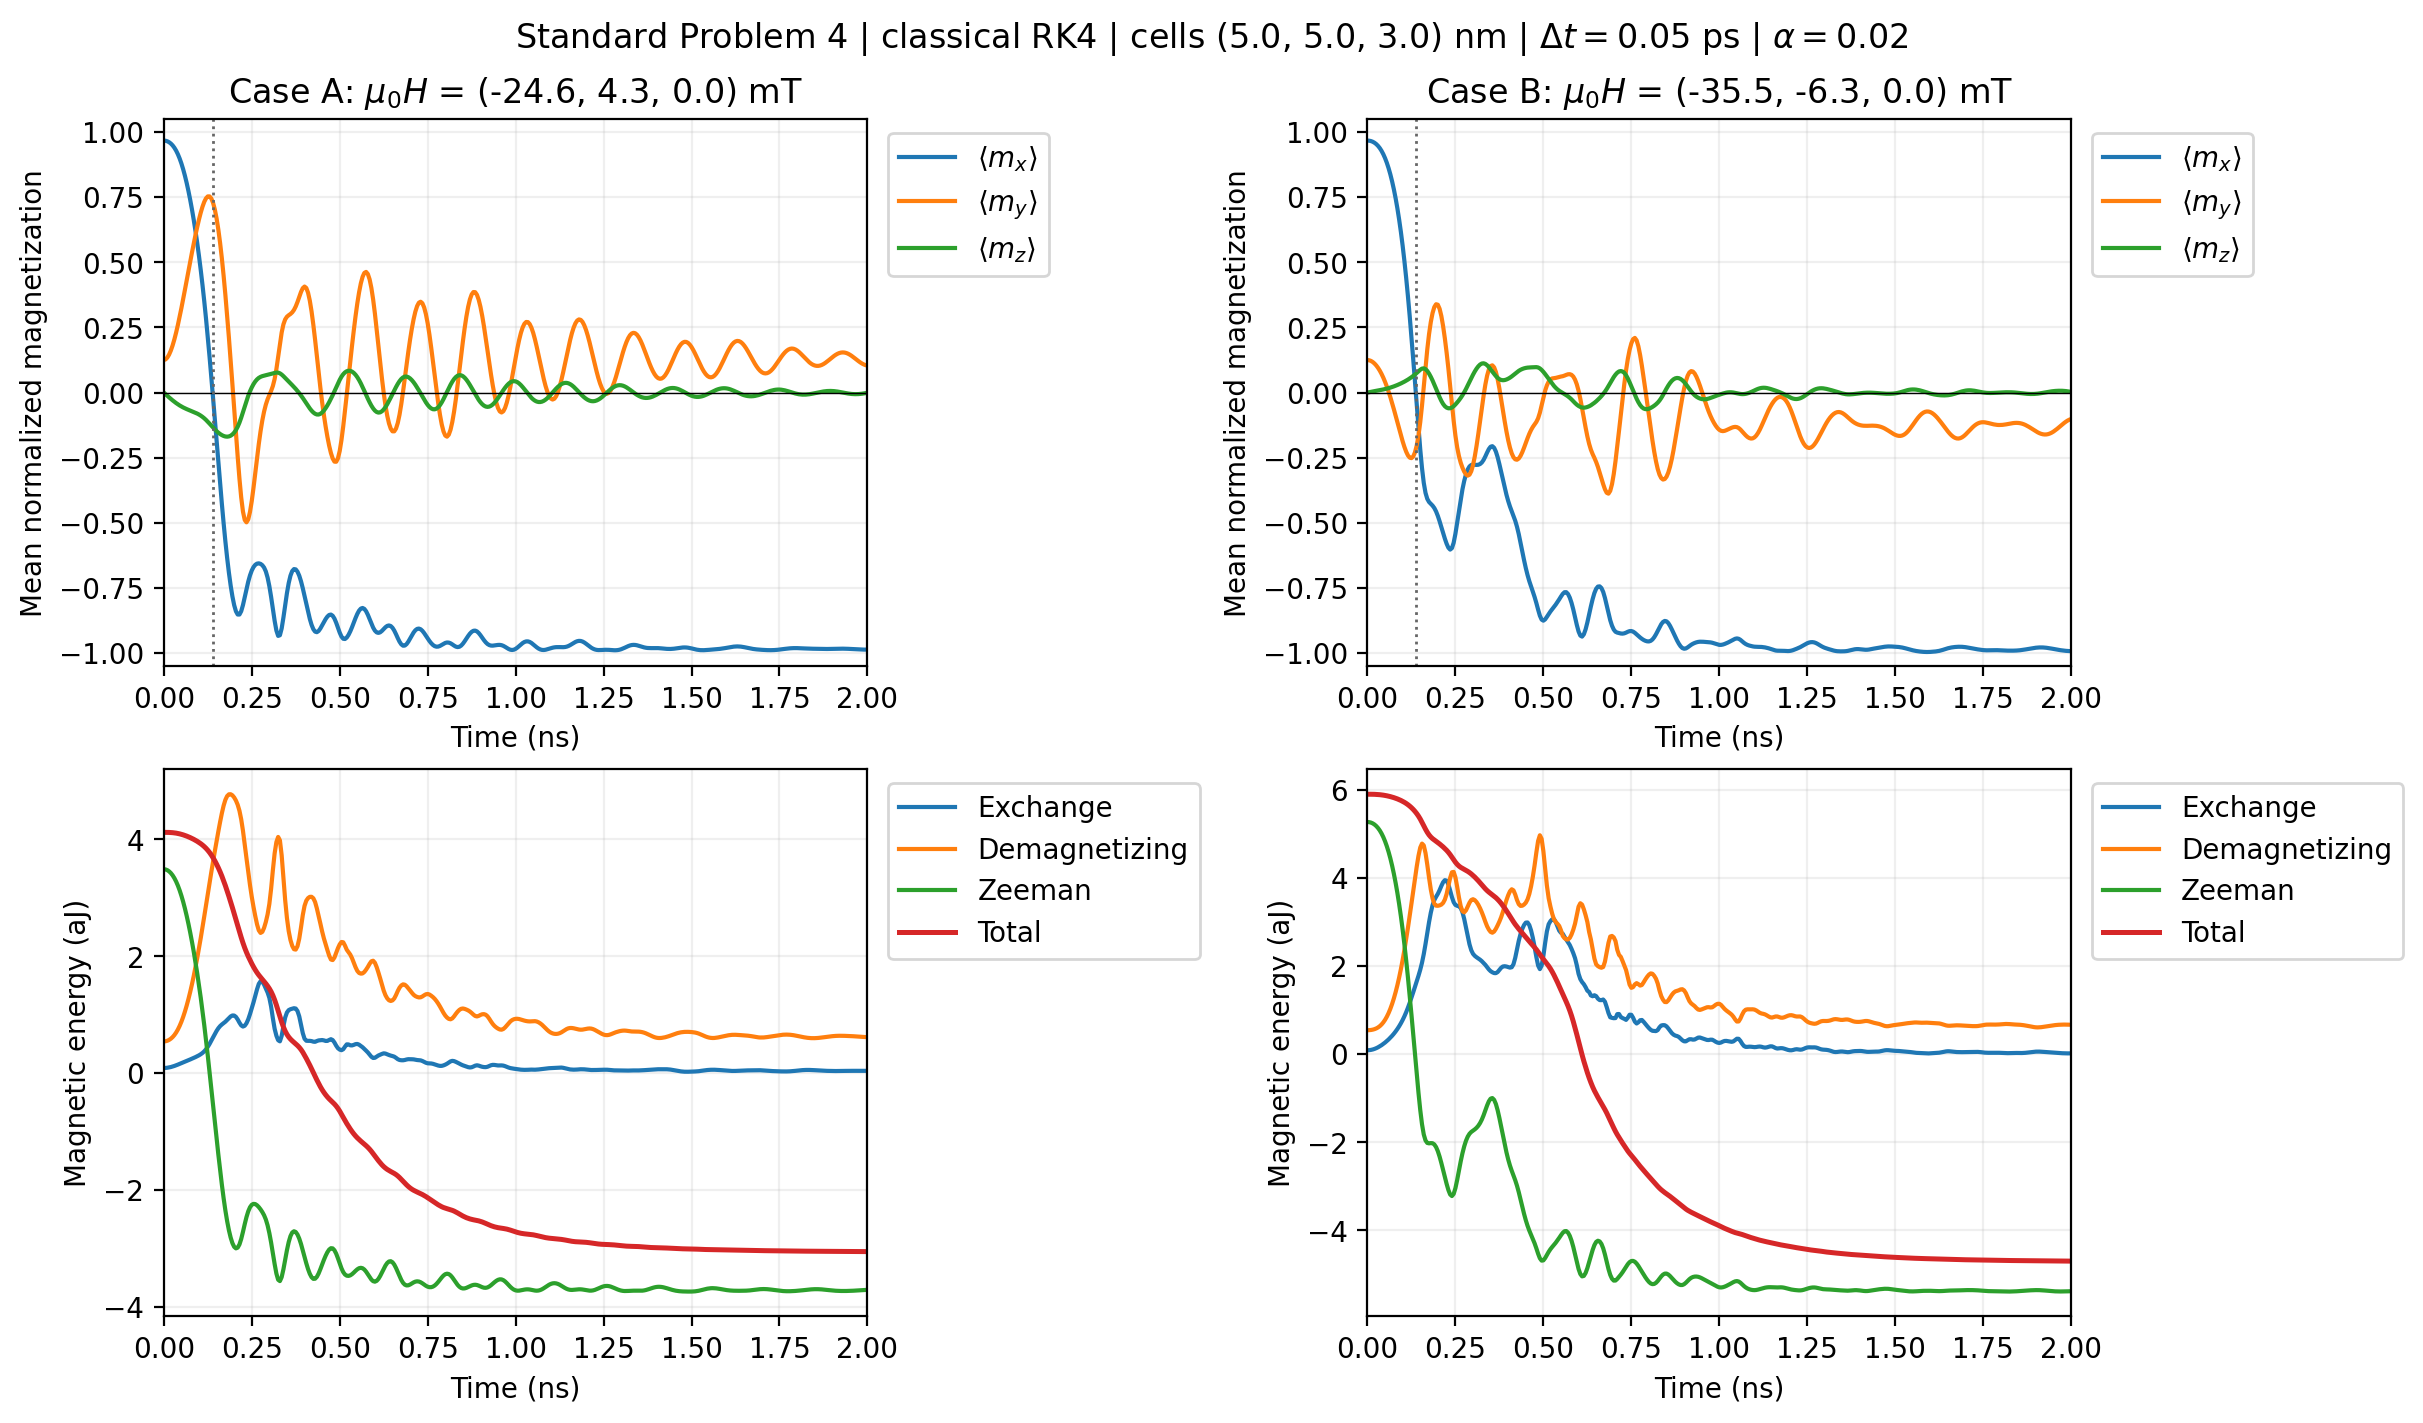

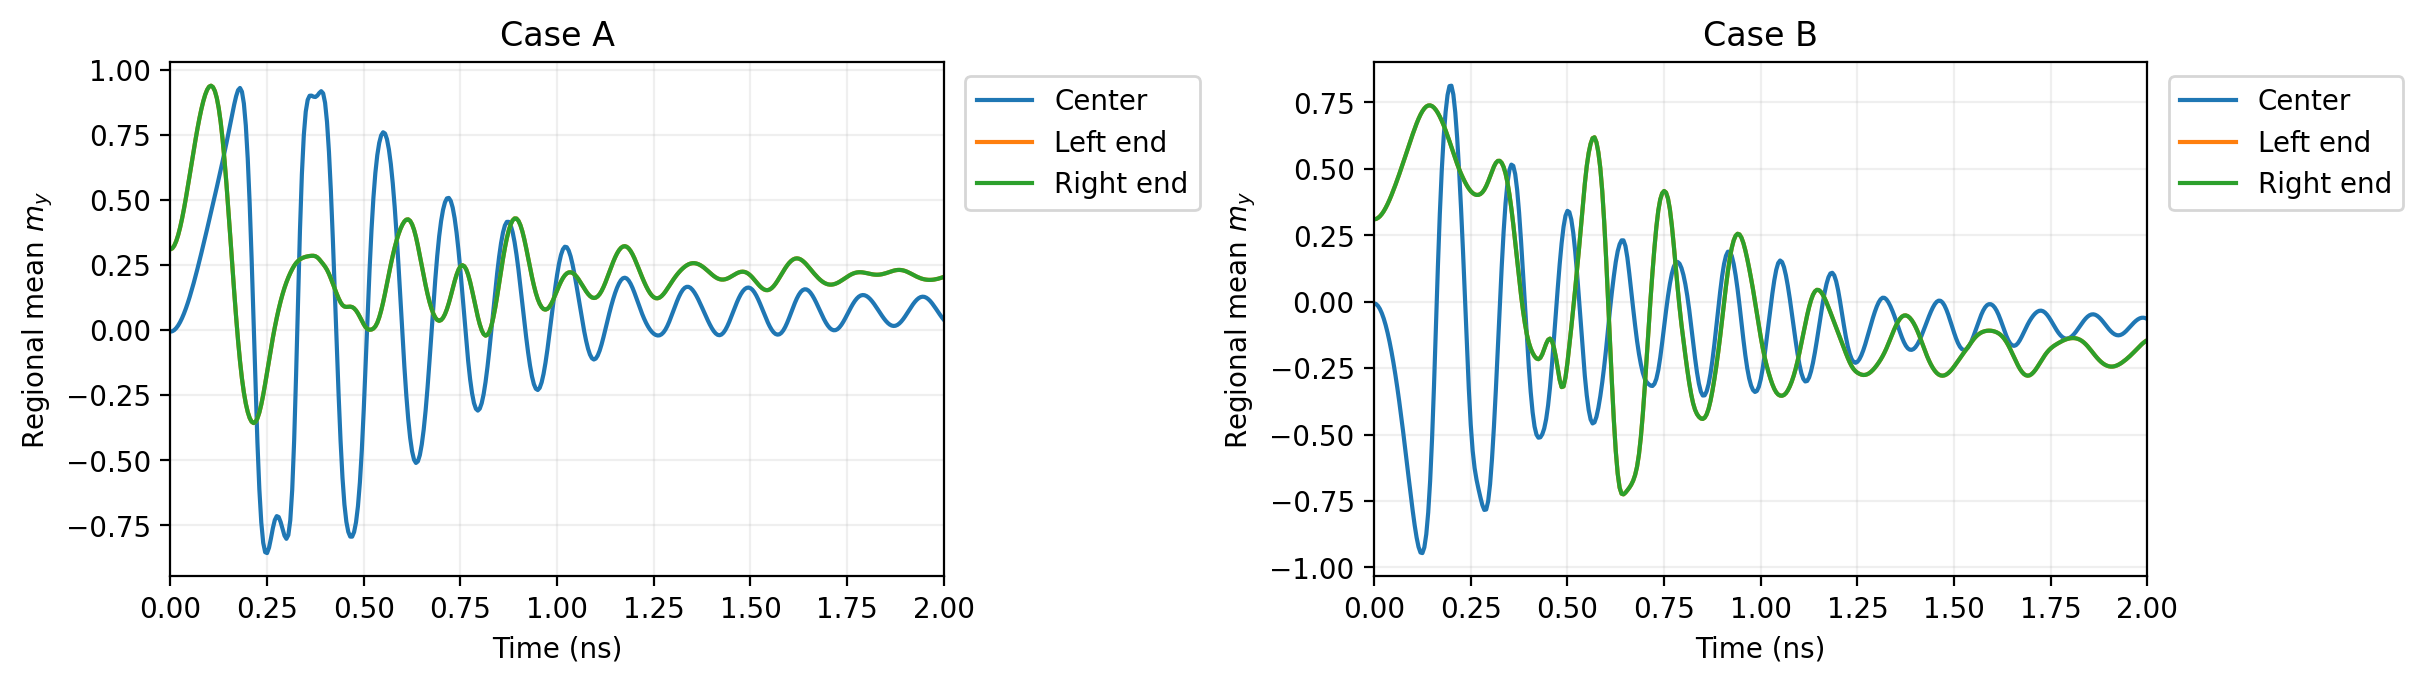

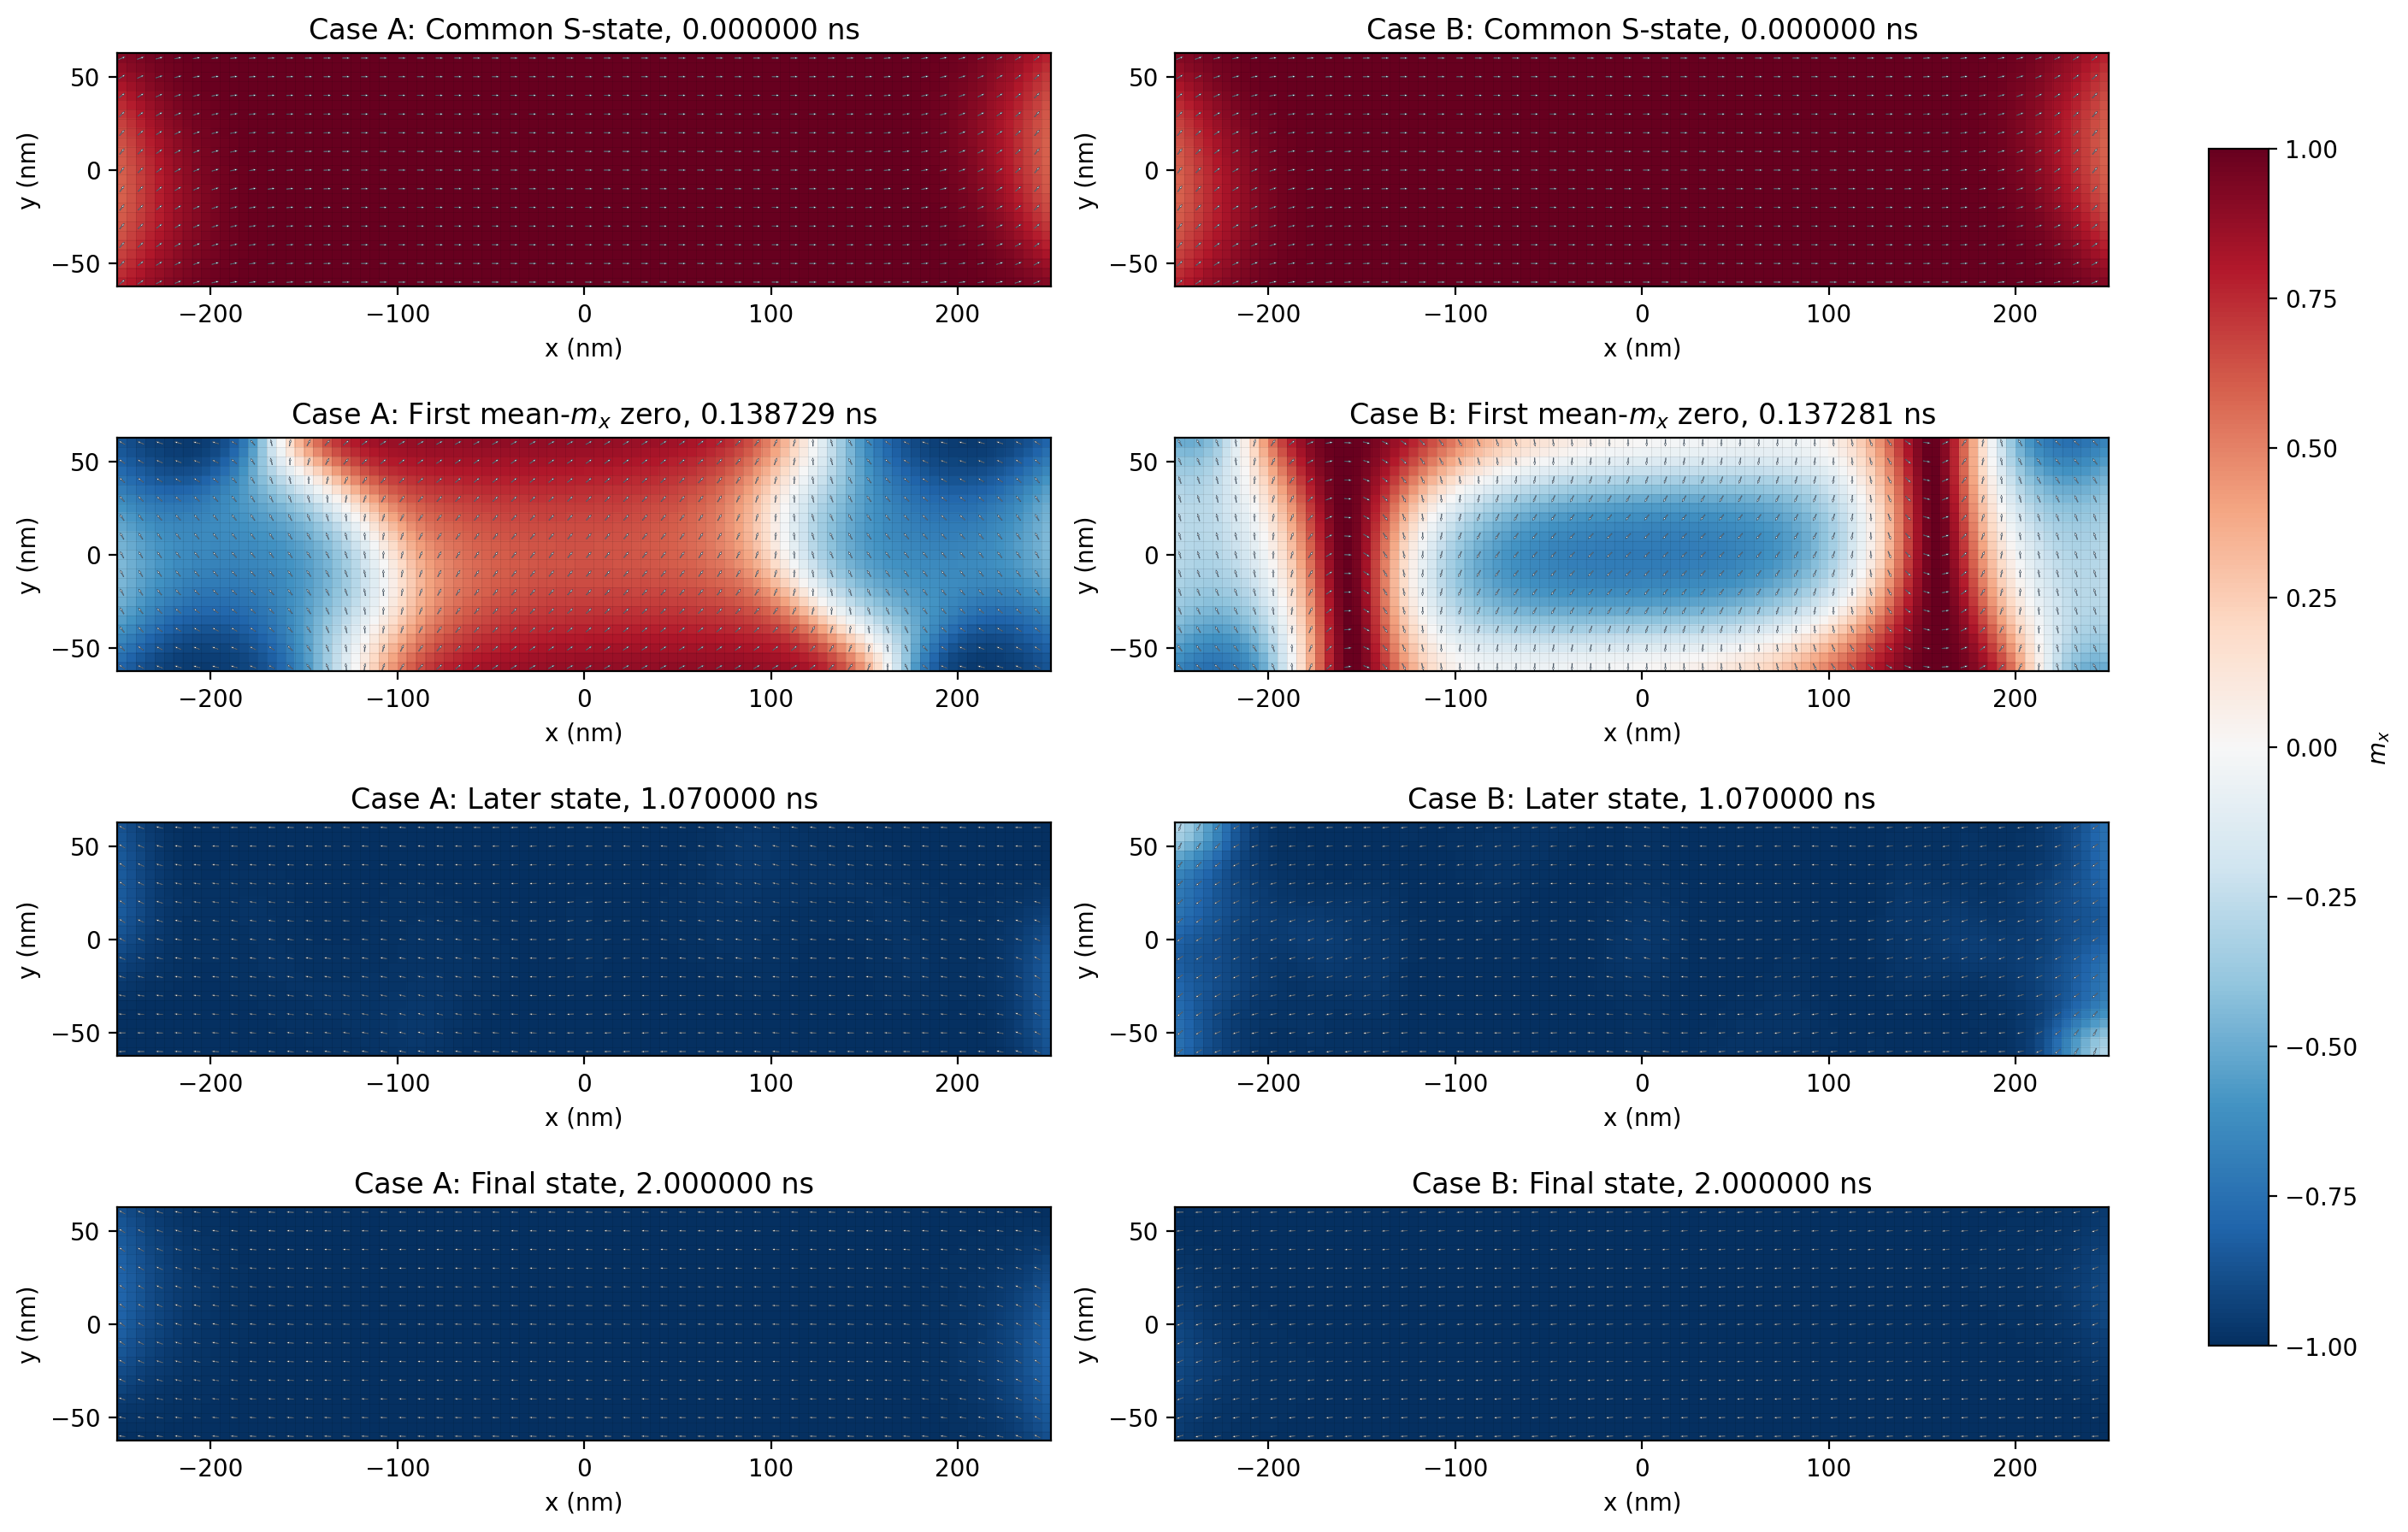

In [9]:
cfg, cases = (RESULTS['cfg'], RESULTS['cases'])
fig, axes = plt.subplots(2, 2, figsize=(12, 7), dpi=cfg.plot_dpi, layout='constrained')
for col, case in enumerate(cases):
    data, crossing = (case['records'], case['crossing'])
    ns = data[:, 0] * 1000000000.0
    for j, name in enumerate('xyz'):
        axes[0, col].plot(ns, data[:, 1 + j], label=f'$\\langle m_{name}\\rangle$')
    axes[0, col].axhline(0, color='black', lw=0.5)
    if crossing is not None:
        axes[0, col].axvline(
            crossing['time_s'] * 1000000000.0, color='0.4', ls=':', lw=1
        )
    axes[0, col].set(
        xlabel='Time (ns)',
        ylabel='Mean normalized magnetization',
        title=f"{case['label']}: $\\mu_0H$ = {case['field_mt']} mT",
        xlim=(0, cfg.duration_ns),
        ylim=(-1.05, 1.05),
    )
    for j, name in enumerate(('Exchange', 'Demagnetizing', 'Zeeman')):
        axes[1, col].plot(ns, data[:, 4 + j] * 1e18, label=name)
    axes[1, col].plot(ns, data[:, 4:7].sum(axis=1) * 1e18, label='Total', lw=1.8)
    axes[1, col].set(
        xlabel='Time (ns)', ylabel='Magnetic energy (aJ)', xlim=(0, cfg.duration_ns)
    )
for ax in axes.flat:
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    ax.grid(alpha=0.2)
fig.suptitle(
    f'Standard Problem 4 | classical RK4 | cells {cfg.cell_nm} nm | $\\Delta t={cfg.dt_ps:g}$ ps | $\\alpha={cfg.alpha:g}$'
)
plt.show()
fig, axes = plt.subplots(
    1, 2, figsize=(12, 3.3), dpi=cfg.plot_dpi, layout='constrained'
)
for ax, case in zip(axes, cases):
    for j, region in enumerate(('Center', 'Left end', 'Right end')):
        ax.plot(
            case['records'][:, 0] * 1000000000.0,
            case['regional_my'][:, j],
            label=region,
        )
    ax.set(
        xlabel='Time (ns)',
        ylabel='Regional mean $m_y$',
        title=case['label'],
        xlim=(0, cfg.duration_ns),
    )
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    ax.grid(alpha=0.2)
plt.show()
fig, axes = plt.subplots(4, 2, figsize=(14, 9), dpi=cfg.plot_dpi, layout='constrained')
for col, case in enumerate(cases):
    frames, times = (case['frames'], case['records'][:, 0])
    crossing = case['crossing']
    if crossing is None:
        indices = np.rint(np.linspace(0, len(frames) - 1, 4)).astype(int)
        states = [(float(times[k]), frames[k], 'Recorded state') for k in indices]
    else:
        target = (crossing['time_s'] + times[-1]) / 2
        middle = int(np.clip(np.argmin(abs(times - target)), 1, len(times) - 2))
        states = [
            (0.0, RESULTS['initial'].reshape(frames.shape[1:]), 'Common S-state'),
            (crossing['time_s'], crossing['frame'], 'First mean-$m_x$ zero'),
            (float(times[middle]), frames[middle], 'Later state'),
            (float(times[-1]), frames[-1], 'Final state'),
        ]
        states = sorted(states, key=itemgetter(0))
    for row, (seconds, state, description) in enumerate(states):
        image, _ = draw_plane(
            axes[row, col],
            state,
            cfg,
            f"{case['label']}: {description}, {seconds * 1000000000.0:.6f} ns",
        )
fig.colorbar(
    image, ax=axes.ravel().tolist(), label=f'$m_{cfg.color_component}$', shrink=0.8
)
plt.show()

## Animation

In [ ]:
cfg, cases = (RESULTS['cfg'], RESULTS['cases'])
count = len(cases[0]['frames'])
ids = np.unique(
    np.rint(np.linspace(0, count - 1, min(cfg.animation_frames, count))).astype(int)
)
with mpl.rc_context({'figure.dpi': cfg.plot_dpi}):
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout='constrained')
    artists = [
        draw_plane(ax, case['frames'][0], cfg, case['label'])
        for ax, case in zip(axes, cases)
    ]
    fig.colorbar(
        artists[0][0], ax=axes.tolist(), label=f'$m_{cfg.color_component}$', shrink=0.8
    )

    def update_animation(k, axes=axes, cases=cases, artists=artists, cfg=cfg):
        """Update both case panels for one recorded time index."""
        FUNCTION_CALLS['update_animation'] += 1
        drawn = []
        for ax, case, (image, arrows) in zip(axes, cases, artists):
            plane = case['frames'][k, case['frames'].shape[1] // 2]
            image.set_data(plane[..., 'xyz'.index(cfg.color_component)])
            arrows.set_verts(glyph_vertices(plane, cfg))
            ax.set_title(
                f"{case['label']}: {case['records'][k, 0] * 1000000000.0:.3f} ns"
            )
            drawn.extend((image, arrows))
        return drawn

    animation = FuncAnimation(
        fig, update_animation, frames=ids, interval=60, blit=False
    )
    html = animation.to_jshtml()
    plt.close(fig)
display(HTML(html))
ANIMATION = animation

## Refinement comparison

In [11]:
if REFINEMENTS:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout='constrained')
    for name, suite in REFINEMENTS.items():
        for ax, base, other in zip(axes, RESULTS['cases'], suite['cases']):
            np.testing.assert_allclose(
                base['records'][:, 0], other['records'][:, 0], rtol=1e-12, atol=1e-21
            )
            delta = np.linalg.norm(
                base['records'][:, 1:4] - other['records'][:, 1:4], axis=1
            )
            ax.plot(base['records'][:, 0] * 1000000000.0, delta, label=name)
            print(
                f"{base['label']}, {name}: max mean-vector difference={delta.max():.4g}"
            )
            if base['crossing'] is not None and other['crossing'] is not None:
                shift_ps = (
                    other['crossing']['time_s'] - base['crossing']['time_s']
                ) * 1000000000000.0
                print(
                    f"{base['label']}, {name}: first-zero time difference={shift_ps:.6g} ps"
                )
    for ax, case in zip(axes, RESULTS['cases']):
        ax.set(
            xlabel='Time (ns)',
            ylabel='Mean-vector difference norm',
            title=case['label'],
        )
        ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
        ax.grid(alpha=0.2)
    plt.show()

else:
    print('Refinement controls are off.')

Refinement controls are off.


In [12]:
# --- Automatic Reuse Check ---
if SHOW_DEFINITION_AUDIT:
    import inspect

    DEFINITION_NAMES = tuple(
        sorted(
            name
            for name, value in list(globals().items())
            if inspect.isfunction(value)
            and inspect.unwrap(value).__globals__ is globals()
        )
    )
    interface_roles = {
        'find_headers': 'CUDA header lookup callback',
        'cudss_context': 'Context manager for native solver lifetime',
        'update_animation': 'Matplotlib frame callback',
    }
    lines = ['| Helper | Executed calls | Decision |', '| --- | ---: | --- |']
    for name in DEFINITION_NAMES:
        count = FUNCTION_CALLS.get(name, 0)
        if name in interface_roles:
            decision = interface_roles[name]
        elif count > FUNCTION_REUSE_THRESHOLD:
            decision = 'Repeated work'
        elif count:
            decision = 'Inline candidate for this run'
        else:
            decision = 'No recorded calls; review if this helper is needed'
        lines.append(f'| `{name}` | {count:,} | {decision} |')
    display(
        Markdown(
            f'**{len(DEFINITION_NAMES)} notebook-defined Python functions.** '
            f'Numerical reuse threshold: more than {FUNCTION_REUSE_THRESHOLD} calls.\n\n'
            + '\n'.join(lines)
        )
    )

**19 notebook-defined Python functions.** Numerical reuse threshold: more than 3 calls.

| Helper | Executed calls | Decision |
| --- | ---: | --- |
| `cudss_context` | 3 | Context manager for native solver lifetime |
| `cudss_residual` | 5,196 | Repeated work |
| `cudss_solve` | 324,504 | Repeated work |
| `demag_field` | 334,100 | Repeated work |
| `draw_plane` | 10 | Repeated work |
| `effective_field` | 328,901 | Repeated work |
| `find_headers` | 1 | CUDA header lookup callback |
| `glyph_vertices` | 214 | Repeated work |
| `magnetic_energy` | 5,199 | Repeated work |
| `newell_f` | 81 | Repeated work |
| `newell_g` | 81 | Repeated work |
| `physical_rate` | 4,398 | Repeated work |
| `relaxation_step` | 4,394 | Repeated work |
| `rk4_step` | 80,027 | Repeated work |
| `safe_ratio` | 729 | Repeated work |
| `stage_velocity` | 320,108 | Repeated work |
| `tangent_basis` | 4,394 | Repeated work |
| `update_animation` | 102 | Matplotlib frame callback |
| `wheel_paths` | 17 | Repeated work |

## References

1. Gilbert, T.L. (2004) 'A phenomenological theory of damping in ferromagnetic materials', *IEEE Transactions on Magnetics*, 40(6), pp. 3443–3449. https://doi.org/10.1109/TMAG.2004.836740
2. Newell, A.J., Williams, W. and Dunlop, D.J. (1993) 'A generalization of the demagnetizing tensor for nonuniform magnetization', *Journal of Geophysical Research: Solid Earth*, 98(B6), pp. 9551–9555. https://doi.org/10.1029/93JB00694
3. Alouges, F. (2008) 'A new finite element scheme for Landau-Lifchitz equations', *Discrete and Continuous Dynamical Systems, Series S*, 1(2), pp. 187–196. https://doi.org/10.3934/dcdss.2008.1.187
4. Vansteenkiste, A., Leliaert, J., Dvornik, M., Helsen, M., Garcia-Sanchez, F. and Van Waeyenberge, B. (2014) 'The design and verification of MuMax3', *AIP Advances*, 4(10), 107133. https://doi.org/10.1063/1.4899186

| Technical resource | Purpose |
|---|---|
| [NIST Standard Problem 4 specification](https://www.ctcms.nist.gov/~rdm/std4/spec4.html) | Geometry, material values, two applied fields, and required comparison outputs |
| [NIST Standard Problem 4 movies and configuration](https://math.nist.gov/oommf/movies/oommf-movies.html) | Independent reference textures, time traces, and example problem files |
| [OOMMF Standard Problem 4 example](https://github.com/fangohr/oommf/blob/master/oommf/app/oxs/examples/stdprob4.mif) | Uniform tilted seed and Gilbert coefficient convention |
| [NVIDIA cuDSS documentation](https://docs.nvidia.com/cuda/cudss/latest/getting_started.html) | Sparse symbolic analysis, numerical factorization, and solve phases |
| [NIST classical RK4 formula](https://dlmf.nist.gov/3.7#v) | Four-stage rule and local fifth-order error |
| [CuPy installation documentation](https://docs.cupy.dev/en/stable/install.html) | Matching CUDA 12 component wheels |
| [CUDA runtime-header lookup](https://nvidia.github.io/cuda-python/cuda-pathfinder/latest/generated/cuda.pathfinder.find_nvidia_header_directory.html) | Header-discovery behavior used by the supplied setup |

## Summary

The notebook computes both field-driven reversal cases from a common relaxed S-state, with classical RK4 advancing the magnetization through four native cuDSS stage solves per step and CuPy evaluating exchange products, demagnetizing fields, and reductions.